# Notebook 7 — Whole-brain tiling of the noise mechanism

We leave the single patch behind. The release is one **global** statistic map (voxelwise group
mean / median / variance) plus a **whole-brain noise field** assembled patch by patch from the
frozen per-patch mechanism (`mech_supervisor_loo_corr`). Where patches overlap, a voxel's noise is
combined from every patch covering it.

**This notebook is constructive + diagnostic, not a privacy evaluation.** Per the meeting, the
per-patch membership question is set aside; the point now is how the *assembled* field behaves as we
vary patch size, shape, and overlap — the object a later privacy eval would attack.

**Substrate.** The committed outputs run on a portable synthetic phantom so they reproduce anywhere;
the real target is **OASIS gray-matter maps** (`USE_OASIS=True`). The synthetic phantom is a testing
stand-in — all interpretation below is written for the OASIS case, and the auto-generated read-offs
recompute from whichever substrate is active.

Conventions: multi-seed with 95% CIs on scalar summaries, concepts in Markdown and result-dependent
interpretation in printed read-offs, and the frozen modules verified byte-unchanged.

## 0 · Setup, configuration, frozen-module check

All sweep dimensions live here. `PROFILE='fast'` is the portable committed run; `'full'` + `USE_OASIS=True`
(with nilearn) is the heavy real-data sweep. `CUSTOM_SIZES` is the hook for the sizes your
autocorrelation notebook (6.3) settles on.

In [1]:
import os
# Pin BLAS to ONE thread per process BEFORE importing numpy. The per-patch matrices are tiny
# (p = 64–512), so BLAS multithreading is pure overhead and oversubscribes cores (this is why
# n_jobs=2 was lighting up ~46 threads). Real parallelism is across PATCHES via joblib n_jobs below.
for _v in ("OMP_NUM_THREADS","OPENBLAS_NUM_THREADS","MKL_NUM_THREADS","NUMEXPR_NUM_THREADS","VECLIB_MAXIMUM_THREADS"):
    os.environ[_v] = "1"
import hashlib, time, warnings, itertools
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib import gridspec
from matplotlib.lines import Line2D
import tiling as T
import privacy_harness as ph

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 120, "savefig.dpi": 120, "font.size": 10,
                     "axes.grid": True, "grid.alpha": 0.25, "axes.axisbelow": True,
                     "axes.spines.top": False, "axes.spines.right": False})

# FROZEN = {
#  "privacy_harness.py": "f03e766b265b4b0b253ce3a8eb94cb53ea76662544ea0b1b9db102f8f29015b4",
#  "cov_diagnostics.py": "d91b33cf7e532ee676d16532830ea65f263a5c0277cc4bd34d768908d2601013",
#  "inference_eval.py":  "0bd08830469858a9332a5cfddc6c332a894dc318b09efda42a9ba8fa6c2b2018"}
# for f, h in FROZEN.items():
#     assert hashlib.sha256(open(f, "rb").read()).hexdigest() == h, f"FROZEN MODULE CHANGED: {f}"
# print("frozen modules verified byte-unchanged:", ", ".join(FROZEN))

In [2]:
# ================= configuration =================
PROFILE   = "full"          # 'fast' = portable committed run; 'full' = heavy sweep (user env)
USE_OASIS = True           # True -> real OASIS gray-matter maps (needs nilearn); the real study

N        = 40               # cohort size (N-1 = 39 is the LOO rank ceiling)
EPSILON  = 1.0              # per-patch mechanism scale (factor = 2/eps); not a DP guarantee
MIN_FRAC = 0.5              # a patch is 'well-estimated' if >= this fraction is in-brain; boundary
                            # patches below it are still added as needed so every voxel gets noise
NJOBS    = 50                # cores here; raise in the user env
MECH_KIND = "l2"             # per-patch mechanism: 'supervisor' (bar=max_i|D_i|) or 'l2' (bar=|D_{i*}|)

SHAPES = {"3x3x3": (3,3,3), "4x4x4": (4,4,4), "8x8x8": (8,8,8),
          "8x8x1": (8,8,1), "2x16x2": (2,16,2)}
DISP   = {"3x3x3":"3³","4x4x4":"4³","8x8x8":"8³","8x8x1":"8×8×1","2x16x2":"2×16×2"}
OVERLAPS = [0.0, 0.25, 0.5]
STATS    = ["mean", "median", "variance"]
PIPES    = {"mean": ph.pipeline_mean, "median": ph.pipeline_median, "variance": ph.pipeline_variance}

# your 6.3 autocorrelation-derived sizes drop in here (name -> (x,y,z))
CUSTOM_SIZES   = {"custom_35x35x35": (35,35,35), "custom_43x30x31": (43,30,31)}
CUSTOM_OVERLAPS = [0.0, 0.25, 0.5]        # committed run keeps custom light; add 0.75 in your env

if PROFILE == "fast":
    PH_SHAPE = (24, 24, 20); SEEDS = (0, 1, 2)
else:
    PH_SHAPE = (48, 48, 40); SEEDS = (0, 1, 2)

# ---- visual system (CVD-safe Okabe-Ito; median=green, variance=orange per request) ----
C_STAT  = {"mean":"#0072B2", "median":"#009E73", "variance":"#E69F00"}
M_STAT  = {"mean":"o", "median":"s", "variance":"^"}
C_BLEND = {"sum":"#555555", "average":"#D55E00", "pou":"#CC79A7", "pou_energy":"#56B4E9"}
BL_DISP = {"sum":"sum (no averaging)", "average":"plain average",
           "pou":"partition-of-unity", "pou_energy":"energy-preserving POU"}
BLENDS_REL = ["average", "pou", "pou_energy"]            # the release blends used for utility
BLENDS_ALL = ["sum", "average", "pou", "pou_energy"]     # all four, for the §3 comparison
CMAP_MAG, CMAP_CNT, CMAP_RANK, CMAP_DIV = "magma", "viridis", "viridis", "RdBu_r"
print(f"PROFILE={PROFILE}  USE_OASIS={USE_OASIS}  vol={PH_SHAPE}  seeds={SEEDS}")

PROFILE=full  USE_OASIS=True  vol=(48, 48, 40)  seeds=(0, 1, 2)


In [3]:
# ---- build the substrate (phantom committed; OASIS behind the flag) ----
t0 = time.perf_counter()
if USE_OASIS:
    SUB = T.load_oasis_volumes(n=max(N, 100)); SUBSTRATE = "OASIS gray-matter maps"
else:
    SUB = T.make_phantom(shape=PH_SHAPE, M=2*N, N=N, corr_lens=(2.0,4.0,6.0),
                         zone_amp=(1.0,0.7,1.3), seed=0)
    SUBSTRATE = f"synthetic phantom {PH_SHAPE} (test substrate)"
MASK = SUB["mask"]; VOLSHAPE = MASK.shape
COHORT = {s: T.sample_cohort(SUB, N, seed=s) for s in SEEDS}   # one cohort per seed (CI variability)
print(f"substrate: {SUBSTRATE}  |  in-brain voxels {int(MASK.sum())}/{MASK.size} "
      f"({MASK.mean()*100:.0f}%)  |  built in {time.perf_counter()-t0:.1f}s")

[fetch_oasis_vbm] Dataset directory found: /users/lukasschuler/nilearn_data/oasis1
substrate: OASIS gray-matter maps  |  in-brain voxels 875291/902629 (97%)  |  built in 4.6s


In [4]:
# ---- plotting helpers ----
zc = VOLSHAPE[2]//2
def show(ax, img, cmap, vmin=None, vmax=None, title=None, outline=None):
    im = ax.imshow(img, origin="lower", cmap=cmap, vmin=vmin, vmax=vmax, interpolation="nearest")
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    if outline is not None:
        ax.contour(outline, levels=[0.5], colors="w", linewidths=0.6, alpha=0.7)
    if title: ax.set_title(title, fontsize=9)
    return im
def robust_sym(vals, q=99):
    a = np.abs(np.asarray(vals)); a = a[np.isfinite(a)]
    v = np.percentile(a, q) if a.size else 1.0; return (-v, v)
def ci95(x):
    x = np.asarray(x, float); x = x[np.isfinite(x)]
    if x.size == 0: return (np.nan, np.nan, np.nan)
    m = x.mean(); sem = x.std(ddof=1)/np.sqrt(len(x)) if len(x) > 1 else 0.0
    return m, m-1.96*sem, m+1.96*sem
MASK_AX = MASK[:,:,zc].T.astype(float)


## 1 · The substrate and its spatial scale

The committed run uses a portable phantom; the real study is OASIS. Two things about the substrate
matter downstream, and each has a figure:

**Inter-subject variability (the SD panels).** The mechanism does not add noise in proportion to the
*signal*; it adds noise in proportion to how much a single subject can move the released statistic —
the per-voxel **sensitivity**. So alongside the three released statistic maps (signal mean / median /
variance over subjects) we show, for each statistic, the per-voxel **standard deviation of its
leave-one-out (LOO) perturbations**, `std_i(d_i)` where `d_i` = statistic(all) − statistic(all but
subject i). That is literally the per-voxel noise scale (`target_sd = 2·std_i(d_i)/ε`): bright SD
regions are where the statistic is most sensitive and therefore where the most noise is injected.
Reading the SD panels tells you *where on the brain the protection burden falls*, per statistic.

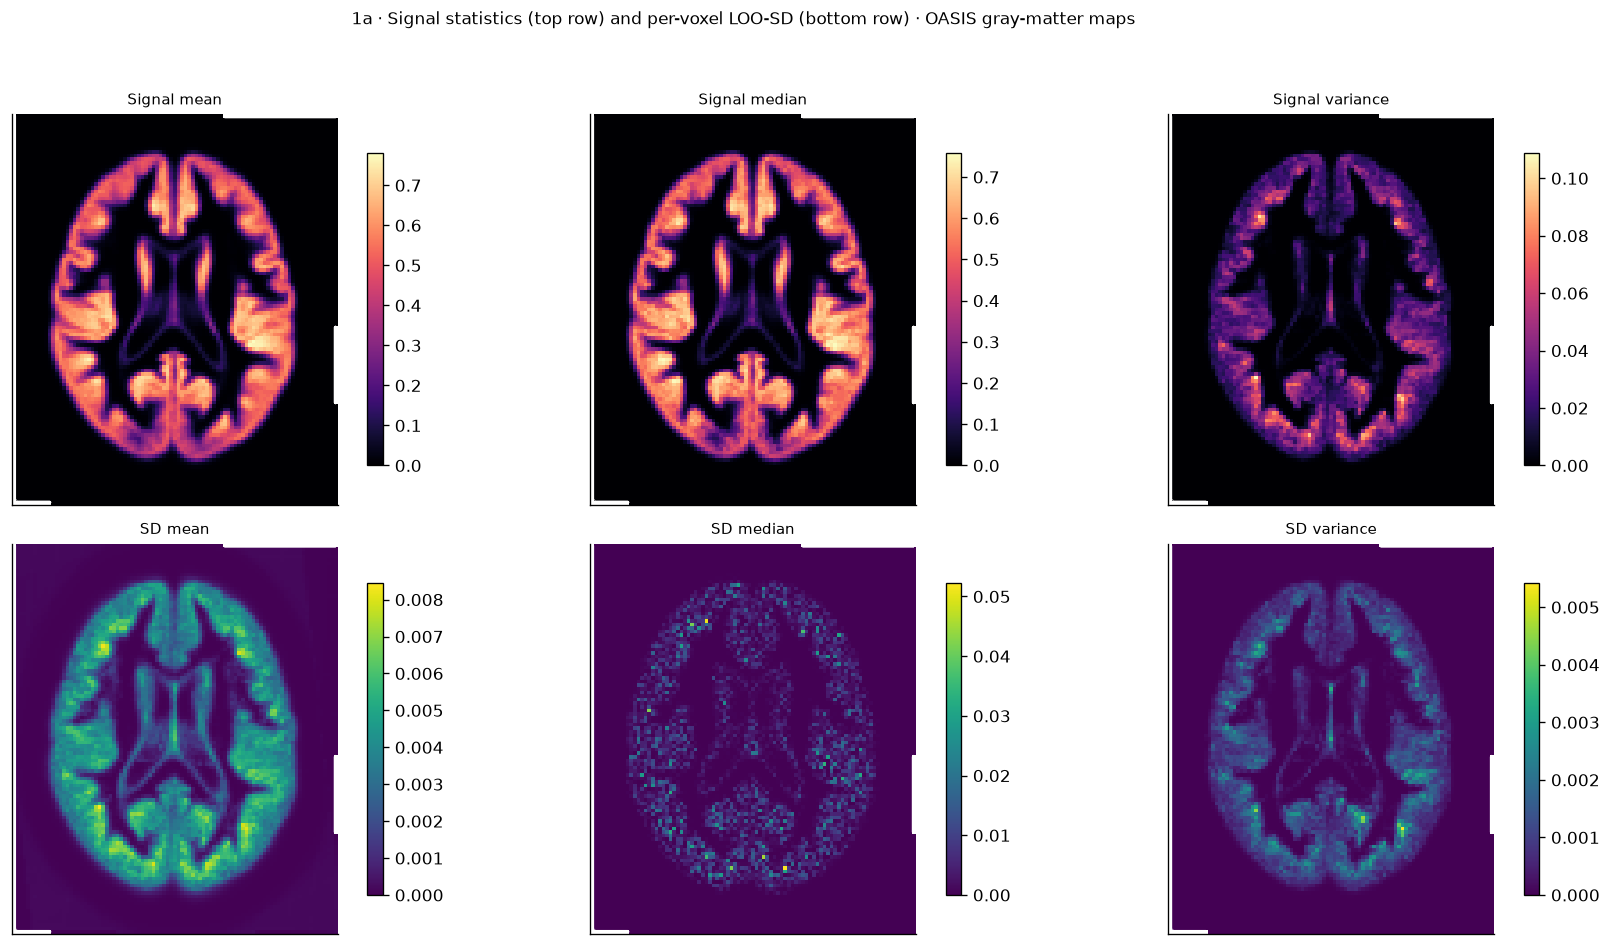

READ-OFF 1a: mean: signal span 0.877, median noise-scale(SD) 0.000138 | median: signal span 0.904, median noise-scale(SD) 0 | variance: signal span 0.174, median noise-scale(SD) 3.59e-06


In [5]:
# Figure 1a — two rows, three columns:
# top: signal mean, median, variance; bottom: corresponding per-voxel LOO-SD
vols0 = COHORT[0]

sig = {
    "mean": vols0.mean(0),
    "median": np.median(vols0, 0),
    "variance": vols0.var(0),
}

sd = {}
for st in STATS:
    _, D, _ = ph.loo_artifacts(vols0, PIPES[st])
    sd[st] = D.std(0)  # per-voxel LOO-perturbation SD

panels = [
    ("Signal mean", sig["mean"], CMAP_MAG),
    ("Signal median", sig["median"], CMAP_MAG),
    ("Signal variance", sig["variance"], CMAP_MAG),
    ("SD mean", sd["mean"], CMAP_CNT),
    ("SD median", sd["median"], CMAP_CNT),
    ("SD variance", sd["variance"], CMAP_CNT),
]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for a, (ttl, m, cmap) in zip(axes.flat, panels):
    im = show(
        a,
        np.where(MASK, m, np.nan)[:, :, zc].T,
        cmap,
        outline=MASK_AX,
    )
    a.set_title(ttl, fontsize=9)
    fig.colorbar(im, ax=a, shrink=0.8)

fig.suptitle(
    f"1a · Signal statistics (top row) and per-voxel LOO-SD (bottom row)"
    f" · {SUBSTRATE}",
    fontsize=10,
)
fig.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

print("READ-OFF 1a: " + " | ".join(
    f"{st}: signal span {np.ptp(sig[st][MASK]):.3g}, "
    f"median noise-scale(SD) {np.median(sd[st][MASK]):.3g}"
    for st in STATS
))

**Radial autocorrelation.** This measures the spatial scale of smoothness: for each distance
("lag") in voxels, how correlated is a voxel with the one that far away, averaged over the brain. The
curve starts at 1 (a voxel equals itself) and decays toward 0; the lag where it crosses 1/e is the
**correlation length**. A short length ⇒ rough field ⇒ patches resolve many independent directions;
a long length ⇒ smooth field ⇒ the noise covariance is low-rank (the notebook-6.1 result). The
vertical bands mark each patch's longest side, so you can see which patches sit *inside* one
correlation blob versus *span several*. On OASIS this length is what your 6.3 sizing method targets.

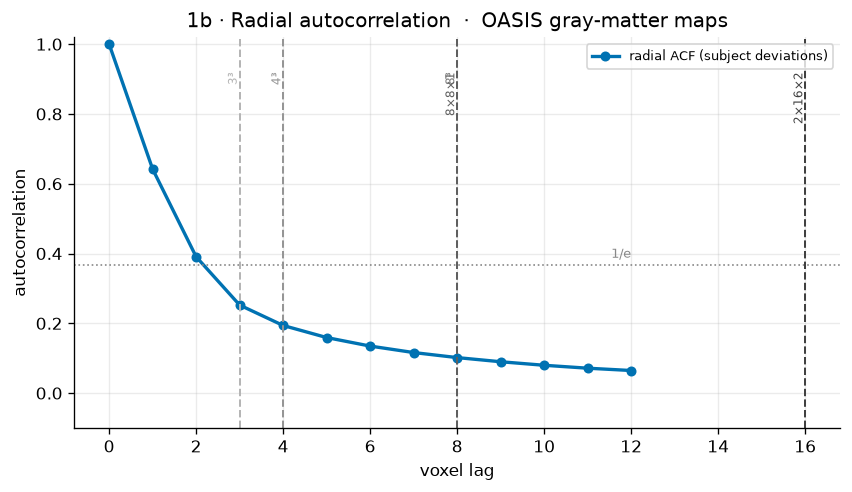

READ-OFF 1b: correlation length (1/e crossing) ≈ 3.0 voxels. Patches whose longest side is below this sit inside one correlation blob (few independent directions); those spanning several lengths resolve more. This is the scale 6.3 sizes patches from.


In [6]:
lags, acf = T.radial_acf(COHORT[0], MASK, max_lag=min(12, min(VOLSHAPE)//2))
fig, ax = plt.subplots(figsize=(7.2, 4.2))
ax.plot(lags, acf, "o-", color="#0072B2", lw=2, ms=5, label="radial ACF (subject deviations)")
ax.axhline(1/np.e, color="#888", ls=":", lw=1); ax.text(lags[-1], 1/np.e+0.02, "1/e", color="#888", ha="right", fontsize=8)
cols = plt.cm.Greys(np.linspace(0.4, 0.8, len(SHAPES)))
for (nm, ps), c in zip(SHAPES.items(), cols):
    ax.axvline(max(ps), color=c, lw=1.2, ls="--"); ax.text(max(ps), 0.92, DISP[nm], rotation=90, va="top", ha="right", fontsize=7, color=c)
cross = lags[np.argmax(acf < 1/np.e)] if np.any(acf < 1/np.e) else np.nan
ax.set_xlabel("voxel lag"); ax.set_ylabel("autocorrelation"); ax.set_ylim(-0.1, 1.02)
ax.set_title(f"1b · Radial autocorrelation  ·  {SUBSTRATE}"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
print(f"READ-OFF 1b: correlation length (1/e crossing) ≈ {cross:.1f} voxels. Patches whose longest "
      f"side is below this sit inside one correlation blob (few independent directions); those spanning "
      f"several lengths resolve more. This is the scale 6.3 sizes patches from.")

## 2 · Tiling geometry

How patches cover the brain at each overlap, and how many pile up on each voxel. Overlap is set by
stride: `stride = round(patch·(1−overlap))`, floored at 1, with the last start anchored to the
volume edge so coverage reaches the far side. **The patch count quoted in each panel below is the
TOTAL number of patches tiled at that setting** (not a per-voxel number); the per-voxel count — how
many patches cover a given voxel — is the separate *coverage-multiplicity* map in Figure 2b.

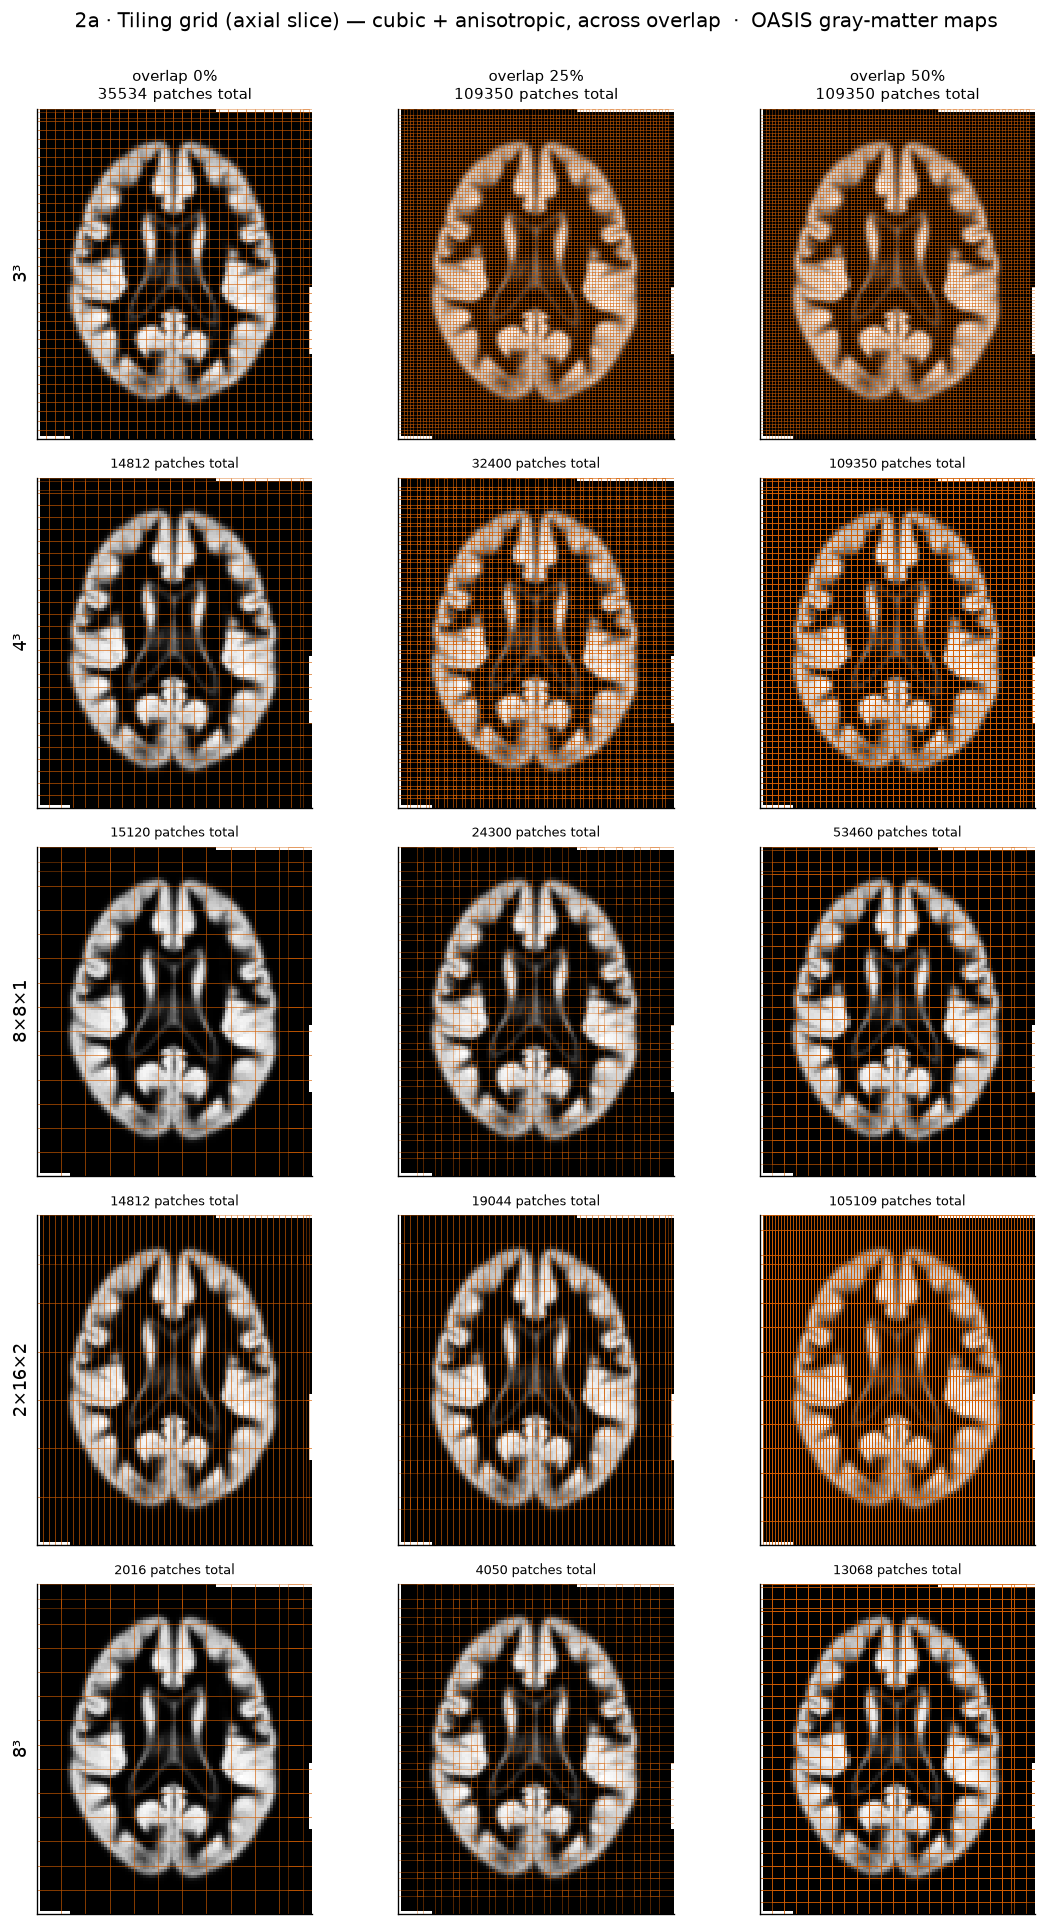

In [5]:
# Figure 2a — tiling grid on one axial slice: 4³ (cubic) and the two anisotropic shapes, across overlap
show_shapes = ["3x3x3","4x4x4", "8x8x1", "2x16x2", "8x8x8"]
fig, axes = plt.subplots(len(show_shapes), len(OVERLAPS), figsize=(3.2*len(OVERLAPS), 3.2*len(show_shapes)))
for i, nm in enumerate(show_shapes):
    ps = SHAPES[nm]
    for j, o in enumerate(OVERLAPS):
        boxes, fr, stride = T.tile_boxes(VOLSHAPE, ps, o, MASK, MIN_FRAC)
        show(axes[i,j], np.where(MASK, COHORT[0].mean(0), np.nan)[:,:,zc].T, "Greys_r")
        for (x0,y0,z0) in boxes:
            if z0 <= zc < z0+ps[2]:
                axes[i,j].add_patch(plt.Rectangle((x0-0.5,y0-0.5), ps[0], ps[1], fill=False,
                                                  edgecolor="#D55E00", lw=0.45, alpha=0.5))
        if i==0: axes[i,j].set_title(f"overlap {int(o*100)}%\n{len(boxes)} patches total", fontsize=9)
        else:    axes[i,j].set_title(f"{len(boxes)} patches total", fontsize=8)
        if j==0: axes[i,j].set_ylabel(DISP[nm], fontsize=11)
fig.suptitle(f"2a · Tiling grid (axial slice) — cubic + anisotropic, across overlap  ·  {SUBSTRATE}", y=1.0)
plt.tight_layout(); plt.show()

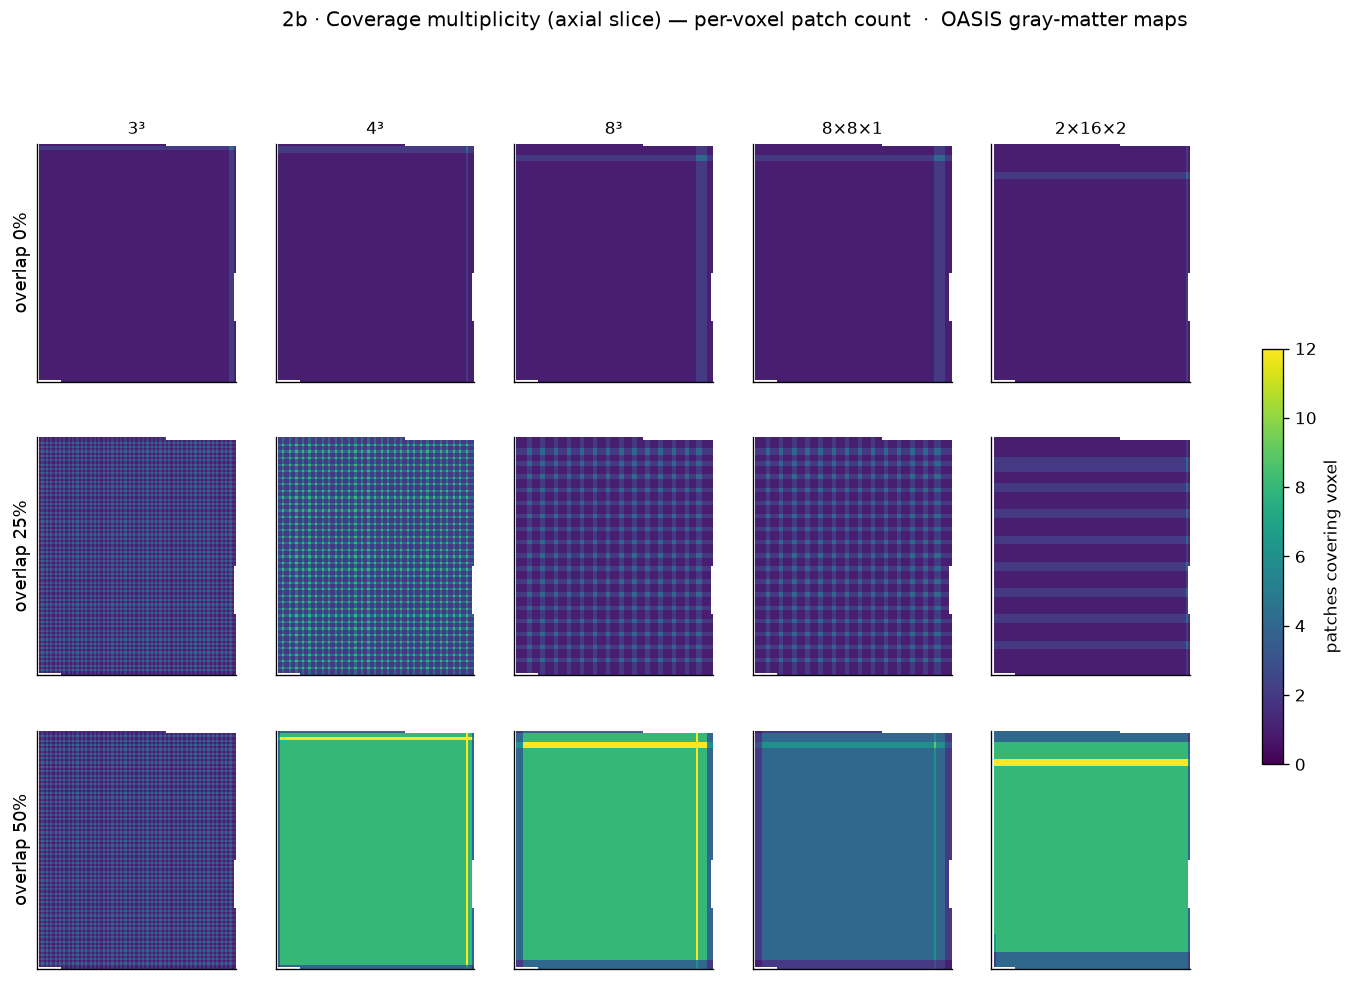

In [8]:
# Figure 2b — coverage multiplicity (rows=overlap, cols=shape)
fig, axes = plt.subplots(
    len(OVERLAPS), len(SHAPES),
    figsize=(3.1 * len(SHAPES), 3.0 * len(OVERLAPS)),
    squeeze=False
)

mult_store = {}
vmax_m = 0

for nm, ps in SHAPES.items():
    for o in OVERLAPS:
        boxes, fr, stride = T.tile_boxes(VOLSHAPE, ps, o, MASK, MIN_FRAC)
        mult = np.zeros(VOLSHAPE)
        for x0, y0, z0 in boxes:
            mult[x0:x0+ps[0], y0:y0+ps[1], z0:z0+ps[2]] += (
                MASK[x0:x0+ps[0], y0:y0+ps[1], z0:z0+ps[2]]
            )
        mult_store[(nm, o)] = mult
        vmax_m = max(vmax_m, np.percentile(mult[MASK], 99))

for i, o in enumerate(OVERLAPS):
    for j, nm in enumerate(SHAPES):
        im = show(
            axes[i, j],
            np.where(MASK, mult_store[(nm, o)], np.nan)[:, :, zc].T,
            CMAP_CNT, vmin=0, vmax=vmax_m
        )
        if i == 0:
            axes[i, j].set_title(DISP[nm], fontsize=10)
        if j == 0:
            axes[i, j].set_ylabel(f"overlap {int(o*100)}%", fontsize=11)

fig.colorbar(im, ax=axes, shrink=0.5, label="patches covering voxel")
fig.suptitle(
    f"2b · Coverage multiplicity (axial slice) — per-voxel patch count  ·  {SUBSTRATE}",
    y=1.0
)
plt.show()

**Patch count vs overlap.** Total patches on a log axis, one line per shape. The key non-obvious
feature is the stride rounding: at a given overlap, `stride = round(patch·(1−overlap))`, so at 75%
overlap 4³ rounds to stride 1 (it tiles every voxel → a huge count), while 6³→round(1.5)=2 and
8³→round(2.0)=2 both land on stride 2 and so stay close to each other. The large gap is 4³ vs the
rest, not 6³ vs 8³.

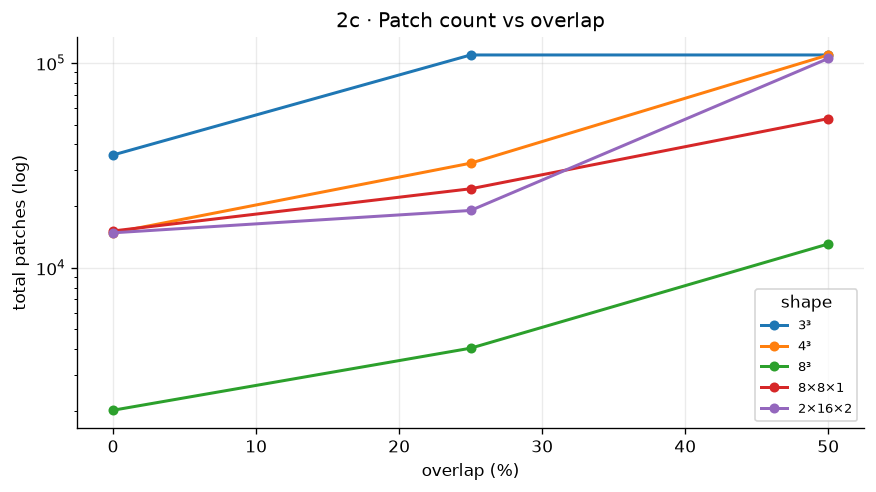

READ-OFF 2c: strides at 75% overlap — 4³→1, 3³→1, 8³→2  (round(patch·0.25): 4·.25=1.0, 3·.25=0.75→1, 8·.25=2.0). The 4³ explosion is the rounding to stride 1; 3³ and 8³ share stride 2 and stay close.


In [9]:
fig, ax = plt.subplots(figsize=(7.4, 4.2))
for nm, ps in SHAPES.items():
    cnts = [len(T.tile_boxes(VOLSHAPE, ps, o, MASK, MIN_FRAC)[0]) for o in OVERLAPS]
    ax.plot([int(o*100) for o in OVERLAPS], cnts, "o-", lw=1.8, ms=5, label=DISP[nm])
ax.set_yscale("log"); ax.set_xlabel("overlap (%)"); ax.set_ylabel("total patches (log)")
ax.set_title("2c · Patch count vs overlap"); ax.legend(fontsize=8, title="shape")
plt.tight_layout(); plt.show()
s75 = {nm: T.stride_from_overlap(SHAPES[nm], 0.75)[0] for nm in ["4x4x4","3x3x3","8x8x8"]}
print(f"READ-OFF 2c: strides at 75% overlap — 4³→{s75['4x4x4']}, 3³→{s75['3x3x3']}, 8³→{s75['8x8x8']}  "
      f"(round(patch·0.25): 4·.25=1.0, 3·.25=0.75→1, 8·.25=2.0). The 4³ explosion is the rounding to "
      f"stride 1; 3³ and 8³ share stride 2 and stay close.")

## 3 · Overlap aggregation — combining overlapping patch noise

When patches overlap, each voxel has several independent noise proposals and we must combine them.
Four rules are compared:

- **sum** — just add all contributions. Magnitude grows wherever patches pile up.
- **plain average** — divide by the coverage count. Averaging k independent draws shrinks noise by
  1/√k, *unevenly* (edges keep full noise, interiors are suppressed) → blotchy, with seams.
- **partition-of-unity (POU)** — tapered (Hann) weights summing to 1 per voxel: patches fade in/out
  at their borders so seams vanish; still shrinks variance (by Σwᵢ²), but smoothly.
- **energy-preserving POU** — same taper, divide by √(Σwᵢ²): smooth seams **and** noise held at full
  designed strength. This is the one carried into the privacy eval.

The figure below shows, for one configuration, (row 1) the four assembled fields, (row 2) plain
average minus each POU version so the size and location of the difference are visible, and (row 3)
the **magnitude** |noise| for two blends next to the sensitivity field — bright regions in |noise|
should track bright regions in sensitivity, i.e. the most protected regions.

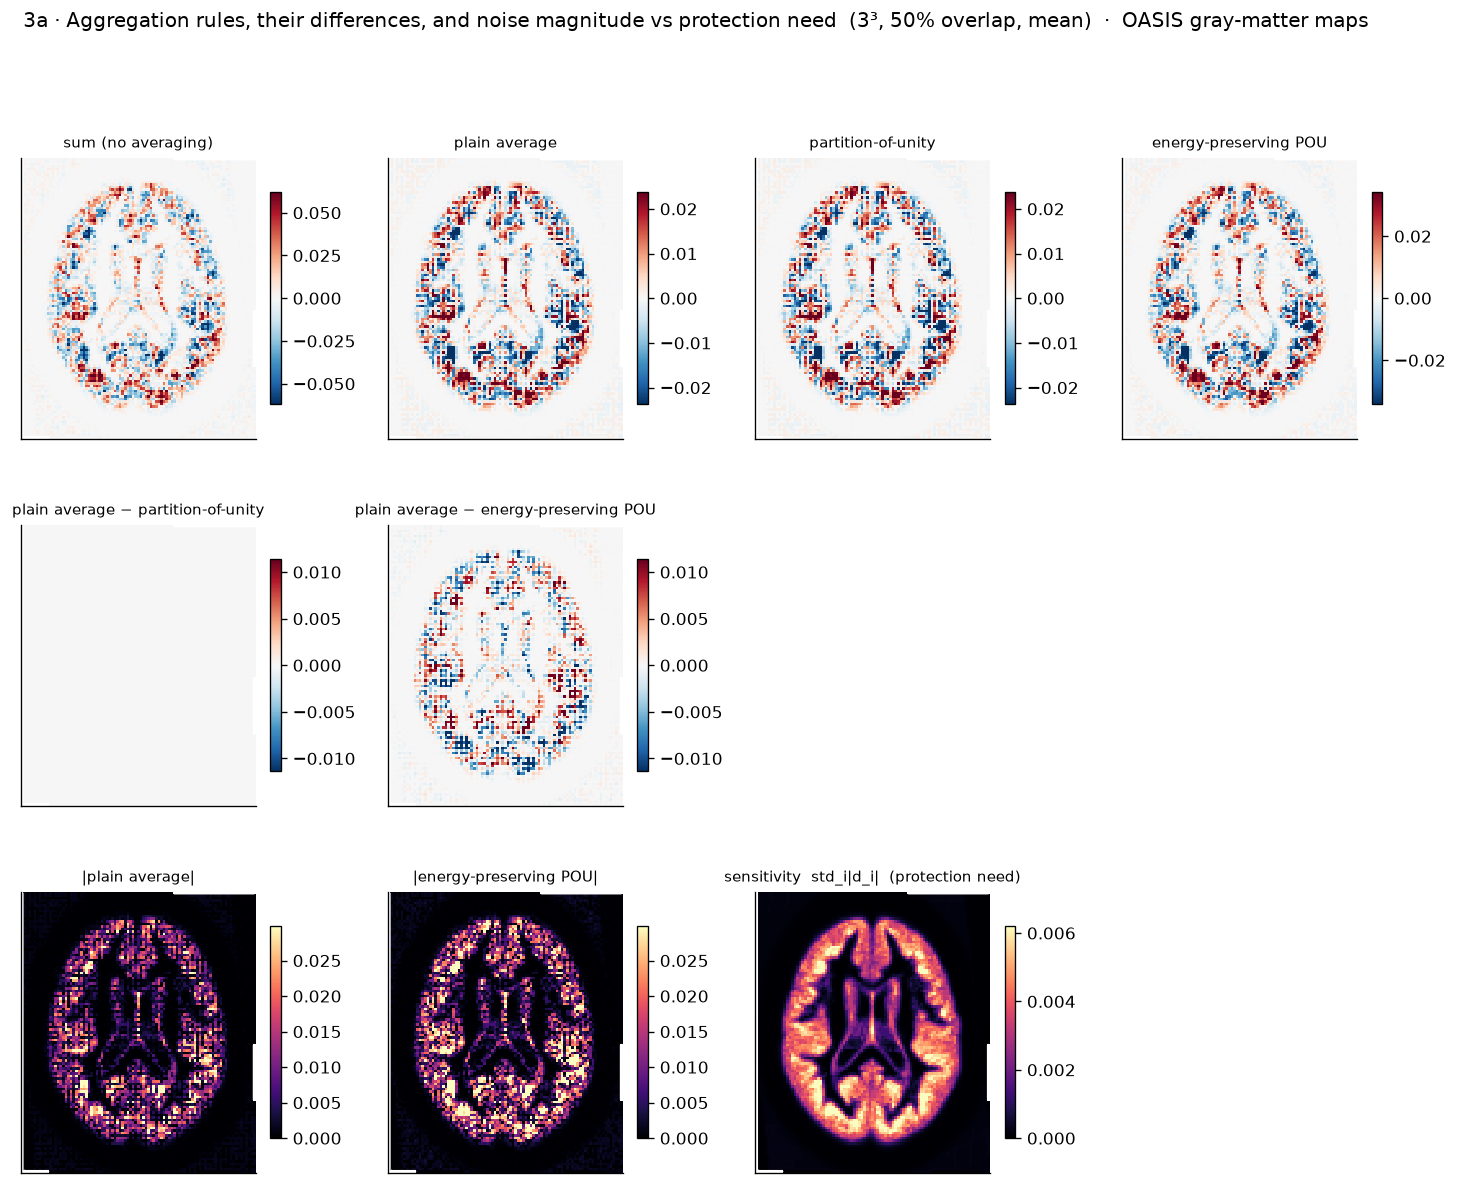

READ-OFF 3a: corr(|energy-POU noise|, sensitivity) = 0.77 — noise magnitude tracks where protection is needed, as the mechanism scales per-voxel noise to local sensitivity.


In [10]:
# compute demo assembles once for §3 (reused across its figures): all statistics at 4³, 50%
demo_shape, demo_ovl = "3x3x3", 0.5
R3 = {st: T.assemble_field(COHORT[0], MASK, st, SHAPES[demo_shape], demo_ovl,
                           epsilon=EPSILON, base_seed=0, min_frac=MIN_FRAC, n_jobs=NJOBS, mech_kind=MECH_KIND) for st in STATS}
_, Dm, _ = ph.loo_artifacts(COHORT[0], PIPES["mean"]); SENS = Dm.std(0)      # mean sensitivity field

F = R3["mean"]["fields"]
fig = plt.figure(figsize=(15, 11)); gs = gridspec.GridSpec(3, 4, figure=fig, hspace=0.3, wspace=0.25)
# row 1: the four fields
for k, b in enumerate(BLENDS_ALL):
    ax = fig.add_subplot(gs[0, k]); vmn, vmx = robust_sym(F[b][MASK])
    im = show(ax, np.where(MASK, F[b], np.nan)[:,:,zc].T, CMAP_DIV, vmin=vmn, vmax=vmx,
              title=BL_DISP[b], outline=MASK_AX); plt.colorbar(im, ax=ax, shrink=0.75)
# row 2: average - POU versions  (SHARED diverging scale across both, for comparability)
diffs = {b: F["average"] - F[b] for b in ["pou", "pou_energy"]}
dvmn, dvmx = robust_sym(np.concatenate([diffs[b][MASK] for b in diffs]))
for k, b in enumerate(["pou", "pou_energy"]):
    ax = fig.add_subplot(gs[1, k])
    im = show(ax, np.where(MASK, diffs[b], np.nan)[:,:,zc].T, CMAP_DIV, vmin=dvmn, vmax=dvmx,
              title=f"plain average − {BL_DISP[b]}", outline=MASK_AX); plt.colorbar(im, ax=ax, shrink=0.75)
# row 3: |noise| for two blends (SHARED magnitude scale) + sensitivity field (own scale: different units)
mag_noise = {"|plain average|": np.abs(F["average"]), "|energy-preserving POU|": np.abs(F["pou_energy"])}
nvmx = np.percentile(np.concatenate([v[MASK] for v in mag_noise.values()]), 99)
for k, (ttl, m) in enumerate(mag_noise.items()):
    ax = fig.add_subplot(gs[2, k])
    im = show(ax, np.where(MASK, m, np.nan)[:,:,zc].T, CMAP_MAG, vmin=0, vmax=nvmx,
              title=ttl, outline=MASK_AX); plt.colorbar(im, ax=ax, shrink=0.75)
ax = fig.add_subplot(gs[2, 2])
im = show(ax, np.where(MASK, SENS, np.nan)[:,:,zc].T, CMAP_MAG, vmin=0, vmax=np.percentile(SENS[MASK], 99),
          title="sensitivity  std_i|d_i|  (protection need)", outline=MASK_AX); plt.colorbar(im, ax=ax, shrink=0.75)
fig.suptitle(f"3a · Aggregation rules, their differences, and noise magnitude vs protection need  "
             f"({DISP[demo_shape]}, 50% overlap, mean)  ·  {SUBSTRATE}", y=0.99)
plt.show()
r = np.corrcoef(np.abs(F["pou_energy"])[MASK], SENS[MASK])[0,1]
print(f"READ-OFF 3a: corr(|energy-POU noise|, sensitivity) = {r:.2f} — noise magnitude "
      f"{'tracks' if r>0.3 else 'only weakly tracks'} where protection is needed, as the mechanism "
      f"scales per-voxel noise to local sensitivity.")

**Seams and magnitude, per statistic.** Two views of what the blends do, now for mean, median
and variance (one row each):

- **Left — line profile across seams.** The x-axis is position along one horizontal row of voxels
  through the brain (a 1-D cut); the y-axis is the noise value at each voxel for each blend. Two
  *separate* things vary here — do not read them as one. (i) **Continuity (smoothness):** plain
  average can show abrupt steps where neighbouring patches meet (seams; clearest at low overlap),
  while POU and energy-POU taper across borders so the curve is continuous — no jumps. (ii)
  **Amplitude:** energy-preserving POU keeps the *full* designed magnitude, so its peaks are the
  **largest** on the plot. Those larger peaks are preserved noise, not roughness — the curve is still
  continuous. So "smoother" here means *seamless*, not *smaller*: plain average is smaller but can
  jump; energy-POU is larger but never jumps.
- **Right — realized noise SD vs coverage multiplicity.** The x-axis is how many patches cover a
  voxel (multiplicity k); the y-axis is the standard deviation of the realized noise among voxels
  with that k. Plain average follows the 1/√k shrink (dotted reference); energy-preserving POU stays
  flat at the designed level — it does not lose magnitude as overlap piles up.

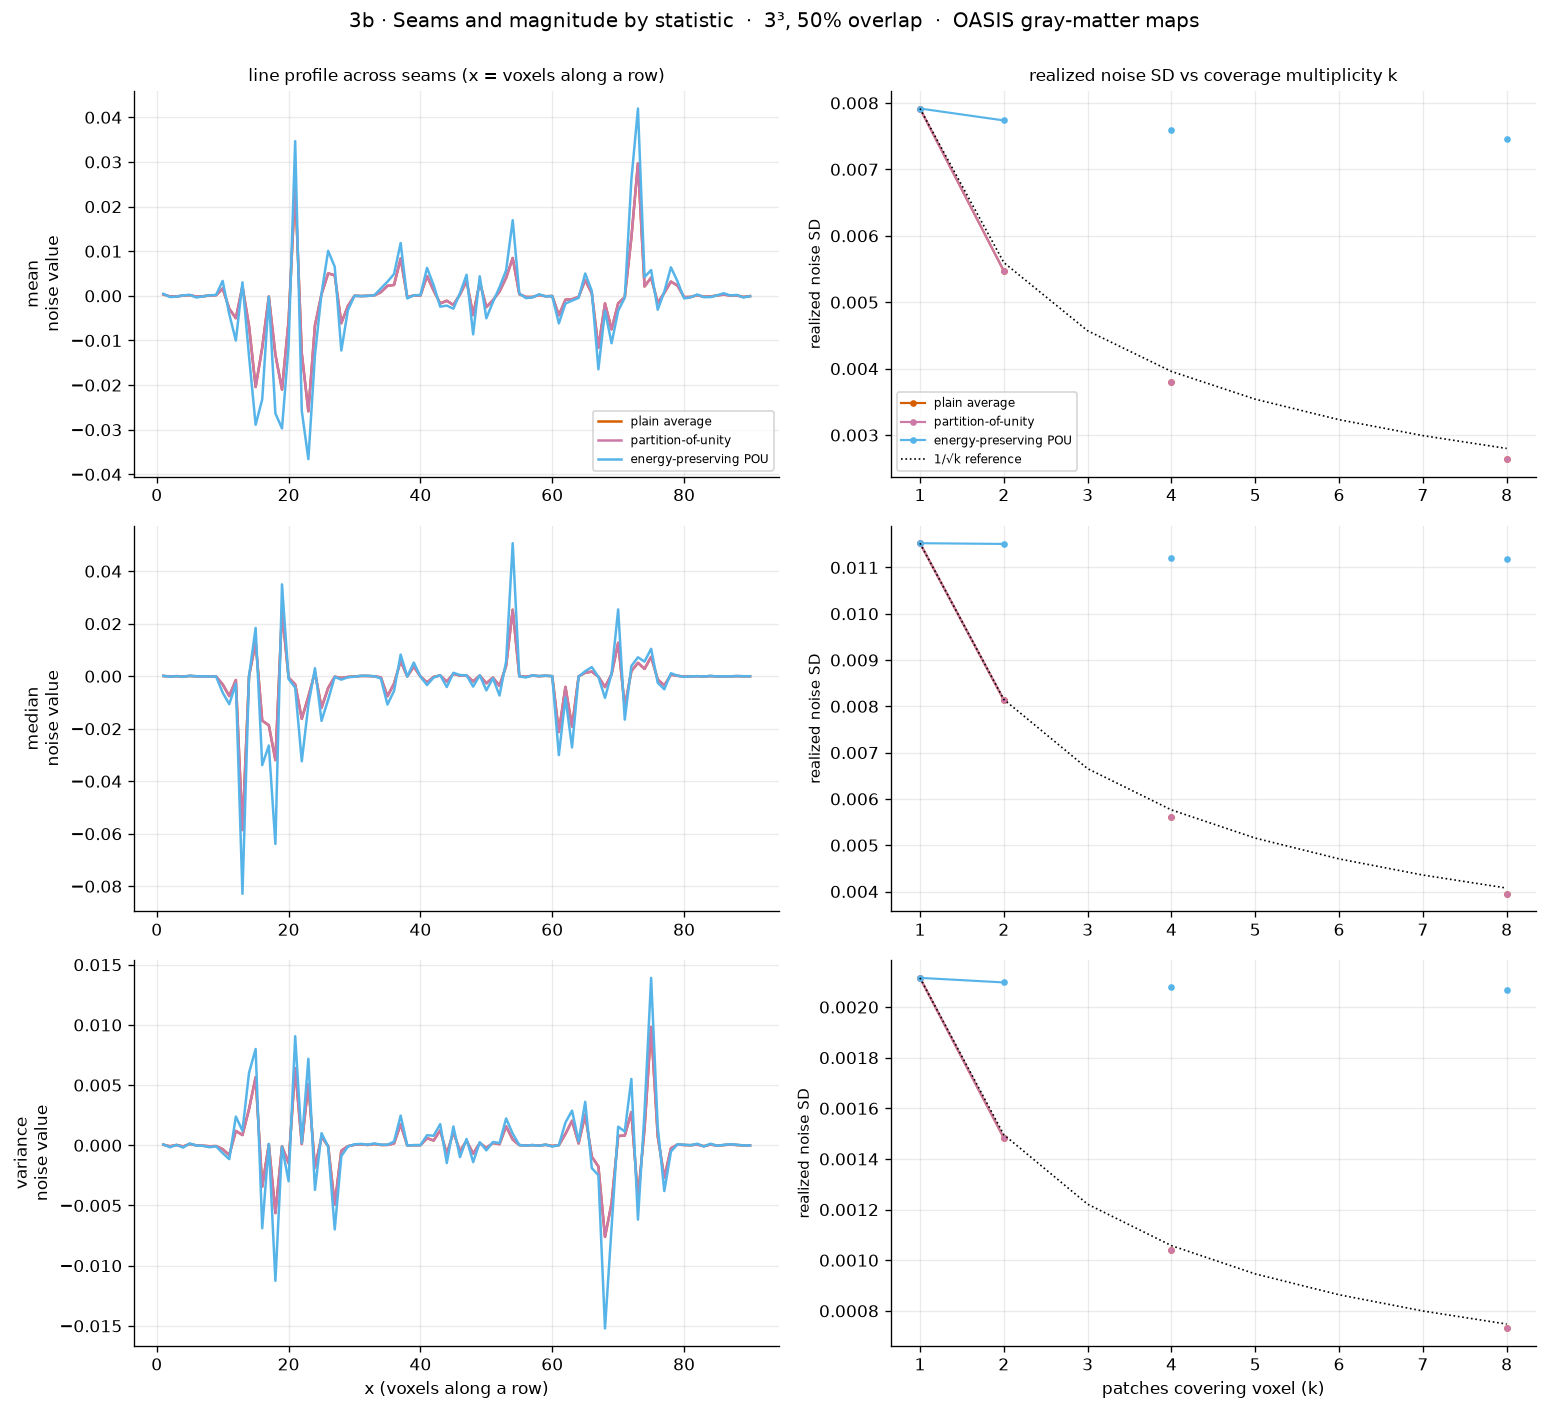

In [11]:
fig, axes = plt.subplots(len(STATS), 2, figsize=(13, 3.9*len(STATS)))
row = VOLSHAPE[1]//2; xs = np.arange(VOLSHAPE[0]); inb = MASK[:, row, zc]
for i, st in enumerate(STATS):
    Fs = R3[st]["fields"]; mult = R3[st]["mult"]; mvals = mult[MASK]
    for b in BLENDS_REL:
        prof = Fs[b][:, row, zc].copy(); prof[~inb] = np.nan
        axes[i,0].plot(xs, prof, color=C_BLEND[b], lw=1.5, label=BL_DISP[b])
    axes[i,0].set_ylabel(f"{st}\nnoise value", fontsize=10)
    if i==0: axes[i,0].set_title("line profile across seams (x = voxels along a row)", fontsize=10); axes[i,0].legend(fontsize=7)
    ks = np.arange(1, int(mvals.max())+1)
    for b in BLENDS_REL:
        f = Fs[b][MASK]; sd_k = [f[np.isclose(mvals,k)].std() for k in ks]
        axes[i,1].plot(ks, sd_k, "o-", color=C_BLEND[b], ms=3, lw=1.3, label=BL_DISP[b])
    base = Fs["average"][MASK]; s1 = base[np.isclose(mvals,1)].std() if np.any(np.isclose(mvals,1)) else np.nan
    if np.isfinite(s1): axes[i,1].plot(ks, s1/np.sqrt(ks), "k:", lw=1, label="1/√k reference")
    if i==0: axes[i,1].set_title("realized noise SD vs coverage multiplicity k", fontsize=10); axes[i,1].legend(fontsize=7)
    axes[i,1].set_ylabel("realized noise SD", fontsize=9)
axes[-1,0].set_xlabel("x (voxels along a row)"); axes[-1,1].set_xlabel("patches covering voxel (k)")
fig.suptitle(f"3b · Seams and magnitude by statistic  ·  {DISP[demo_shape]}, 50% overlap  ·  {SUBSTRATE}", y=1.0)
plt.tight_layout(); plt.show()

## 4 · Noise field and utility

The main sweep: for every statistic × shape × overlap × seed we assemble the field (all blends share
the per-patch draws) and measure whole-brain utility against the clean statistic. Seed-0 fields and
per-patch ranks are cached for the maps here and in §5; utility is aggregated across seeds for 95%
CIs. The released error equals the noise field (noisy − clean = field), so the field maps *are* the
error maps.

**Border voxels — a fixed issue.** With a quality threshold `min_frac` alone, in-brain voxels near
the edge fall only under patches that are mostly outside the brain; those patches get dropped, and
the voxels would be released **with no noise** (a privacy hole). `tiling.tile_boxes` now adds the
minimal boundary patches needed so **every** in-brain voxel is covered, while still estimating each
patch's covariance from its in-brain voxels. The cell below quantifies the hole before/after.

In [12]:
# Border-voxel coverage: uncovered in-brain voxels with the threshold alone vs with the coverage pass
rows = []
for nm, ps in SHAPES.items():
    b_no, _, _  = T.tile_boxes(VOLSHAPE, ps, 0.0, MASK, MIN_FRAC, cover=False)
    b_yes, _, _ = T.tile_boxes(VOLSHAPE, ps, 0.0, MASK, MIN_FRAC, cover=True)
    def uncov(boxes):
        cov = np.zeros(VOLSHAPE)
        for (x0,y0,z0) in boxes: cov[x0:x0+ps[0],y0:y0+ps[1],z0:z0+ps[2]] += MASK[x0:x0+ps[0],y0:y0+ps[1],z0:z0+ps[2]]
        return int(((cov==0)&MASK).sum())
    tot = int(MASK.sum())
    rows.append((DISP[nm], len(b_no), 100*uncov(b_no)/tot, len(b_yes), 100*uncov(b_yes)/tot))
cov_tbl = pd.DataFrame(rows, columns=["shape","patches(no cover)","% uncov(no cover)","patches(cover)","% uncov(cover)"])
print("Border coverage at 0% overlap (the worst case):\n")
print(cov_tbl.round(1).to_string(index=False))
print("\nREAD-OFF 4(border): the coverage pass drives uncovered in-brain voxels to 0 for every shape, "
      "at a modest patch-count increase; without it, large patches leave a substantial unprotected rim.")

Border coverage at 0% overlap (the worst case):

 shape  patches(no cover)  % uncov(no cover)  patches(cover)  % uncov(cover)
    3³              35462                0.1           35534             0.0
    4³              14811                0.0           14812             0.0
    8³               2016                0.0            2016             0.0
 8×8×1              15120                0.0           15120             0.0
2×16×2              14715                0.3           14812             0.0

READ-OFF 4(border): the coverage pass drives uncovered in-brain voxels to 0 for every shape, at a modest patch-count increase; without it, large patches leave a substantial unprotected rim.


In [13]:
# ---- the sweep (computed once; reused by §4 and §5) ----
import time
from datetime import timedelta

def _duration(seconds):
    return str(timedelta(seconds=int(round(seconds))))

n_configs = len(STATS) * len(SHAPES) * len(OVERLAPS)
n_runs = n_configs * len(SEEDS)
completed = 0

SW = {}
UTIL = []
t0 = time.perf_counter()

print(
    f"Starting sweep: {n_configs} configs × {len(SEEDS)} seeds "
    f"= {n_runs} runs; {len(BLENDS_REL)} blends per run.\n"
    "Estimated time remaining will appear after the first run.",
    flush=True,
)

for st in STATS:
    for nm, ps in SHAPES.items():
        for o in OVERLAPS:
            for si, seed in enumerate(SEEDS):
                print(
                    f"[{completed + 1}/{n_runs}] Starting: "
                    f"stat={st} | shape={nm} {ps} | overlap={o} | seed={seed}",
                    flush=True,
                )
                run_t0 = time.perf_counter()

                R = T.assemble_field(
                    COHORT[seed], MASK, st, ps, o,
                    epsilon=EPSILON,
                    base_seed=1000 * seed,
                    min_frac=MIN_FRAC,
                    n_jobs=NJOBS,
                    mech_kind=MECH_KIND,
                )

                if si == 0:
                    SW[(st, nm, o)] = R

                for b in BLENDS_REL:
                    U = T.whole_brain_utility(
                        R["clean"], R["fields"][b], MASK
                    )
                    UTIL.append({
                        "stat": st,
                        "shp": nm,
                        "overlap": o,
                        "blend": b,
                        "seed": seed,
                        **U,
                    })

                completed += 1
                now = time.perf_counter()
                elapsed = now - t0
                remaining = (elapsed / completed) * (n_runs - completed)

                print(
                    f"    Finished in {_duration(now - run_t0)} | "
                    f"{completed / n_runs:.1%} complete | "
                    f"elapsed {_duration(elapsed)} | "
                    f"remaining ≈ {_duration(remaining)}",
                    flush=True,
                )

UTIL = pd.DataFrame(UTIL)

print(
    f"\nSweep complete: {len(SW)} configs × {len(SEEDS)} seeds "
    f"× {len(BLENDS_REL)} blends in "
    f"{_duration(time.perf_counter() - t0)}.",
    flush=True,
)

Starting sweep: 45 configs × 3 seeds = 135 runs; 3 blends per run.
Estimated time remaining will appear after the first run.
[1/135] Starting: stat=mean | shape=3x3x3 (3, 3, 3) | overlap=0.0 | seed=0
    Finished in 0:00:05 | 0.7% complete | elapsed 0:00:05 | remaining ≈ 0:11:47
[2/135] Starting: stat=mean | shape=3x3x3 (3, 3, 3) | overlap=0.0 | seed=1
    Finished in 0:00:05 | 1.5% complete | elapsed 0:00:10 | remaining ≈ 0:11:17
[3/135] Starting: stat=mean | shape=3x3x3 (3, 3, 3) | overlap=0.0 | seed=2
    Finished in 0:00:05 | 2.2% complete | elapsed 0:00:15 | remaining ≈ 0:11:16
[4/135] Starting: stat=mean | shape=3x3x3 (3, 3, 3) | overlap=0.25 | seed=0
    Finished in 0:00:11 | 3.0% complete | elapsed 0:00:27 | remaining ≈ 0:14:30
[5/135] Starting: stat=mean | shape=3x3x3 (3, 3, 3) | overlap=0.25 | seed=1
    Finished in 0:00:12 | 3.7% complete | elapsed 0:00:38 | remaining ≈ 0:16:32
[6/135] Starting: stat=mean | shape=3x3x3 (3, 3, 3) | overlap=0.25 | seed=2
    Finished in 0:00:1

**Assembled noise field across shape and overlap (mean statistic).** Rows are patch shape, columns
are overlap; each cell is one axial slice of the energy-preserving POU field on a shared colour scale,
so cells are directly comparable. Look for how the spatial texture of the noise changes as patches
shrink/grow and as overlap increases.

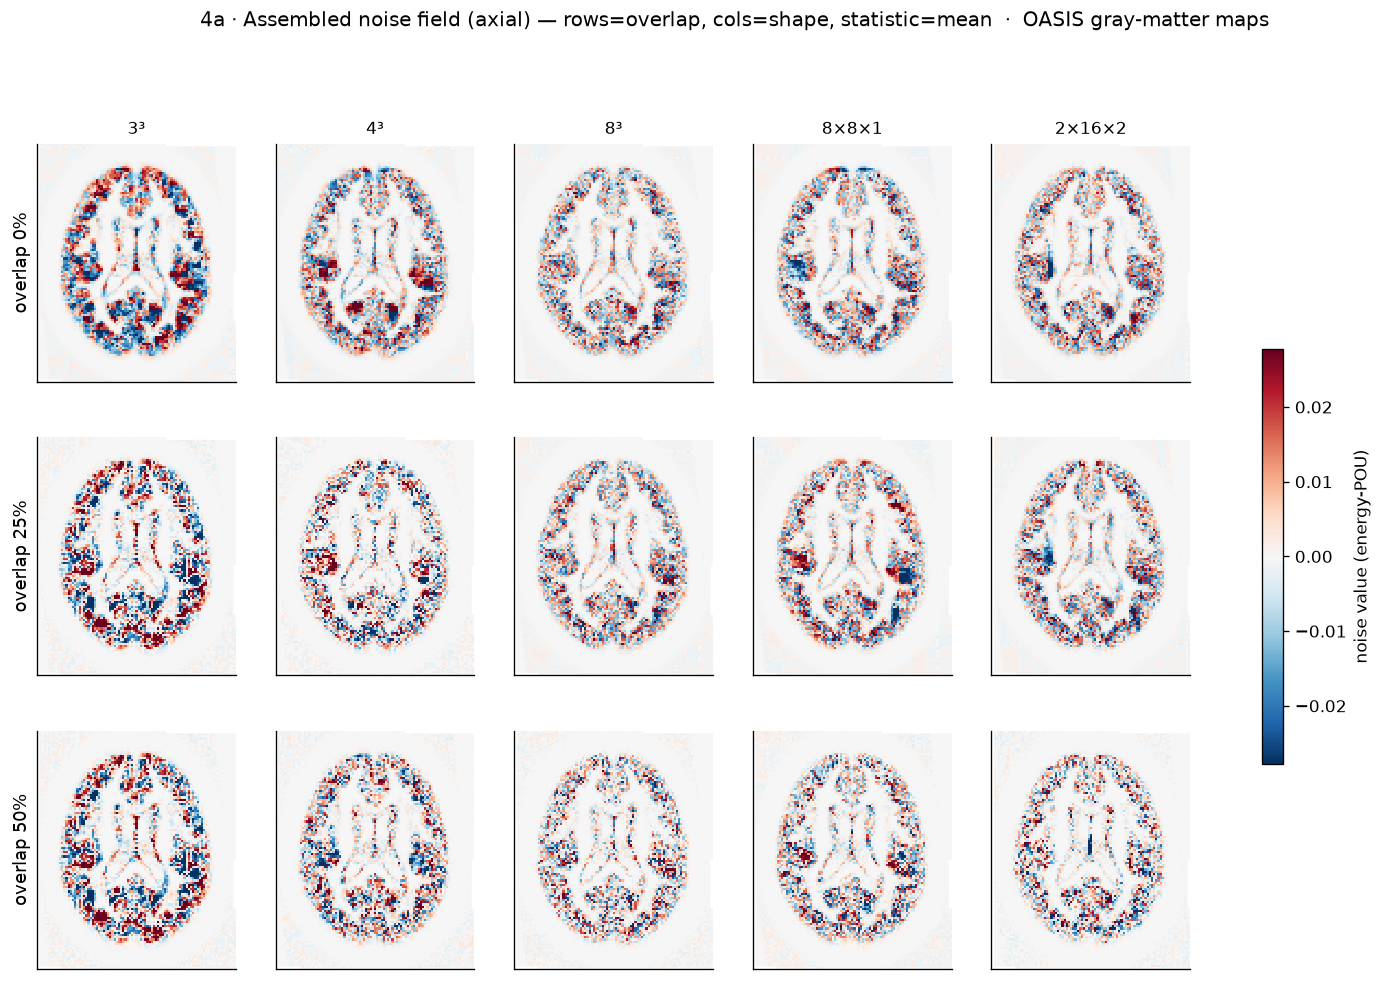

In [14]:
grid_stat = "mean"
allf = [
    SW[(grid_stat, nm, o)]["fields"]["pou_energy"][MASK]
    for nm in SHAPES for o in OVERLAPS
]
vmn, vmx = robust_sym(np.concatenate(allf))

fig, axes = plt.subplots(
    len(OVERLAPS), len(SHAPES),
    figsize=(3.1 * len(SHAPES), 3.0 * len(OVERLAPS)),
    squeeze=False,
)

for i, o in enumerate(OVERLAPS):
    for j, nm in enumerate(SHAPES):
        im = show(
            axes[i, j],
            np.where(
                MASK,
                SW[(grid_stat, nm, o)]["fields"]["pou_energy"],
                np.nan,
            )[:, :, zc].T,
            CMAP_DIV, vmin=vmn, vmax=vmx, outline=MASK_AX,
        )
        if i == 0:
            axes[i, j].set_title(DISP[nm], fontsize=10)
        if j == 0:
            axes[i, j].set_ylabel(f"overlap {int(o * 100)}%", fontsize=11)

fig.colorbar(im, ax=axes, shrink=0.5, label="noise value (energy-POU)")
fig.suptitle(
    f"4a · Assembled noise field (axial) — "
    f"rows=overlap, cols=shape, statistic={grid_stat}  ·  {SUBSTRATE}",
    y=1.0,
)
plt.show()

**The release, in three panels per statistic.** Left is the clean statistic map; middle is the
assembled noise field that gets added; right is the **noisy release** (clean + noise) — what actually
leaves the pipeline. One row per statistic, for a representative configuration.

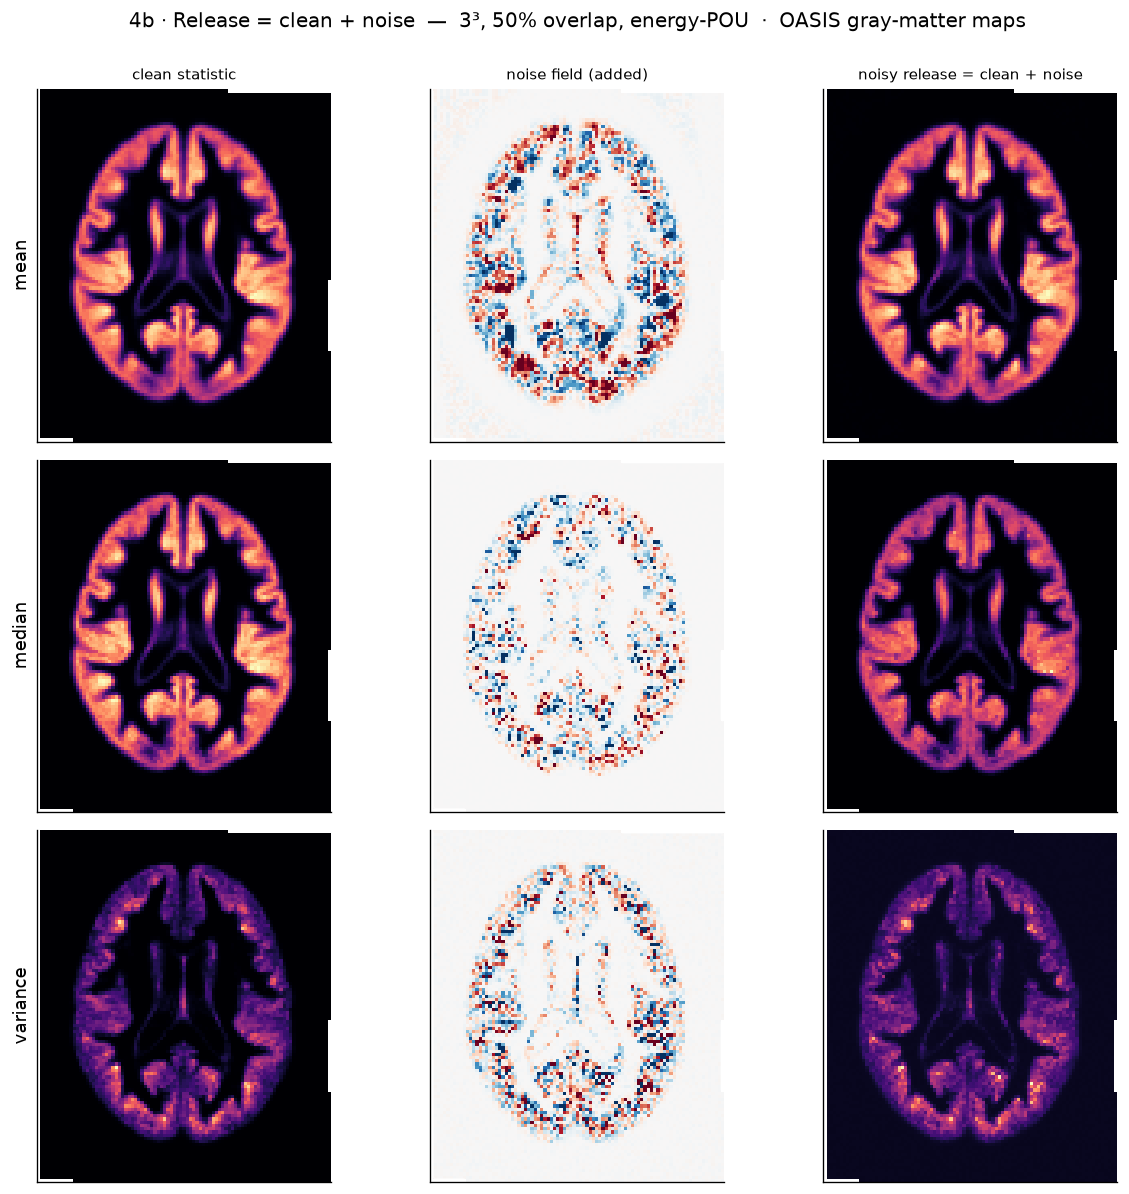

In [15]:
tri_shape, tri_ovl = "3x3x3", 0.5
fig, axes = plt.subplots(len(STATS), 3, figsize=(10.5, 3.3*len(STATS)))
for i, st in enumerate(STATS):
    R = SW[(st, tri_shape, tri_ovl)]; fld = R["fields"]["pou_energy"]; clean = R["clean"]
    vmn, vmx = robust_sym(fld[MASK])
    show(axes[i,0], np.where(MASK, clean, np.nan)[:,:,zc].T, CMAP_MAG, title="clean statistic" if i==0 else None)
    show(axes[i,1], np.where(MASK, fld, np.nan)[:,:,zc].T, CMAP_DIV, vmin=vmn, vmax=vmx,
         title="noise field (added)" if i==0 else None, outline=MASK_AX)
    show(axes[i,2], np.where(MASK, clean+fld, np.nan)[:,:,zc].T, CMAP_MAG, title="noisy release = clean + noise" if i==0 else None)
    axes[i,0].set_ylabel(st, fontsize=11)
fig.suptitle(f"4b · Release = clean + noise  —  {DISP[tri_shape]}, 50% overlap, energy-POU  ·  {SUBSTRATE}", y=1.0)
plt.tight_layout(); plt.show()

### 4c · Utility metrics

The harness `utility_panel` offers four measures; we use the three that capture distinct failure
modes here (bias-norm, the fourth, checks rejection-sampling bias and is ≈0 for this mechanism, so it
is omitted from the plot):

- **rel-MSE** — magnitude of distortion (noise power / signal power); lower is better.
- **neighbour-corr gap** — |spatial neighbour-correlation(clean) − neighbour-correlation(released)|;
  the *imaging-specific* axis that MSE is blind to (iid noise inflates it). Lower is better.
- **Spearman** — rank/ordering preservation across voxels; 1 means the ordering is intact.

Rows are the three metrics, columns are the statistics, lines are the blends, x is overlap, with 95%
CI bands over seeds. Watch that plain average's *lower* rel-MSE at high overlap is noise shrinkage —
the same effect would reduce privacy — whereas energy-POU holds.

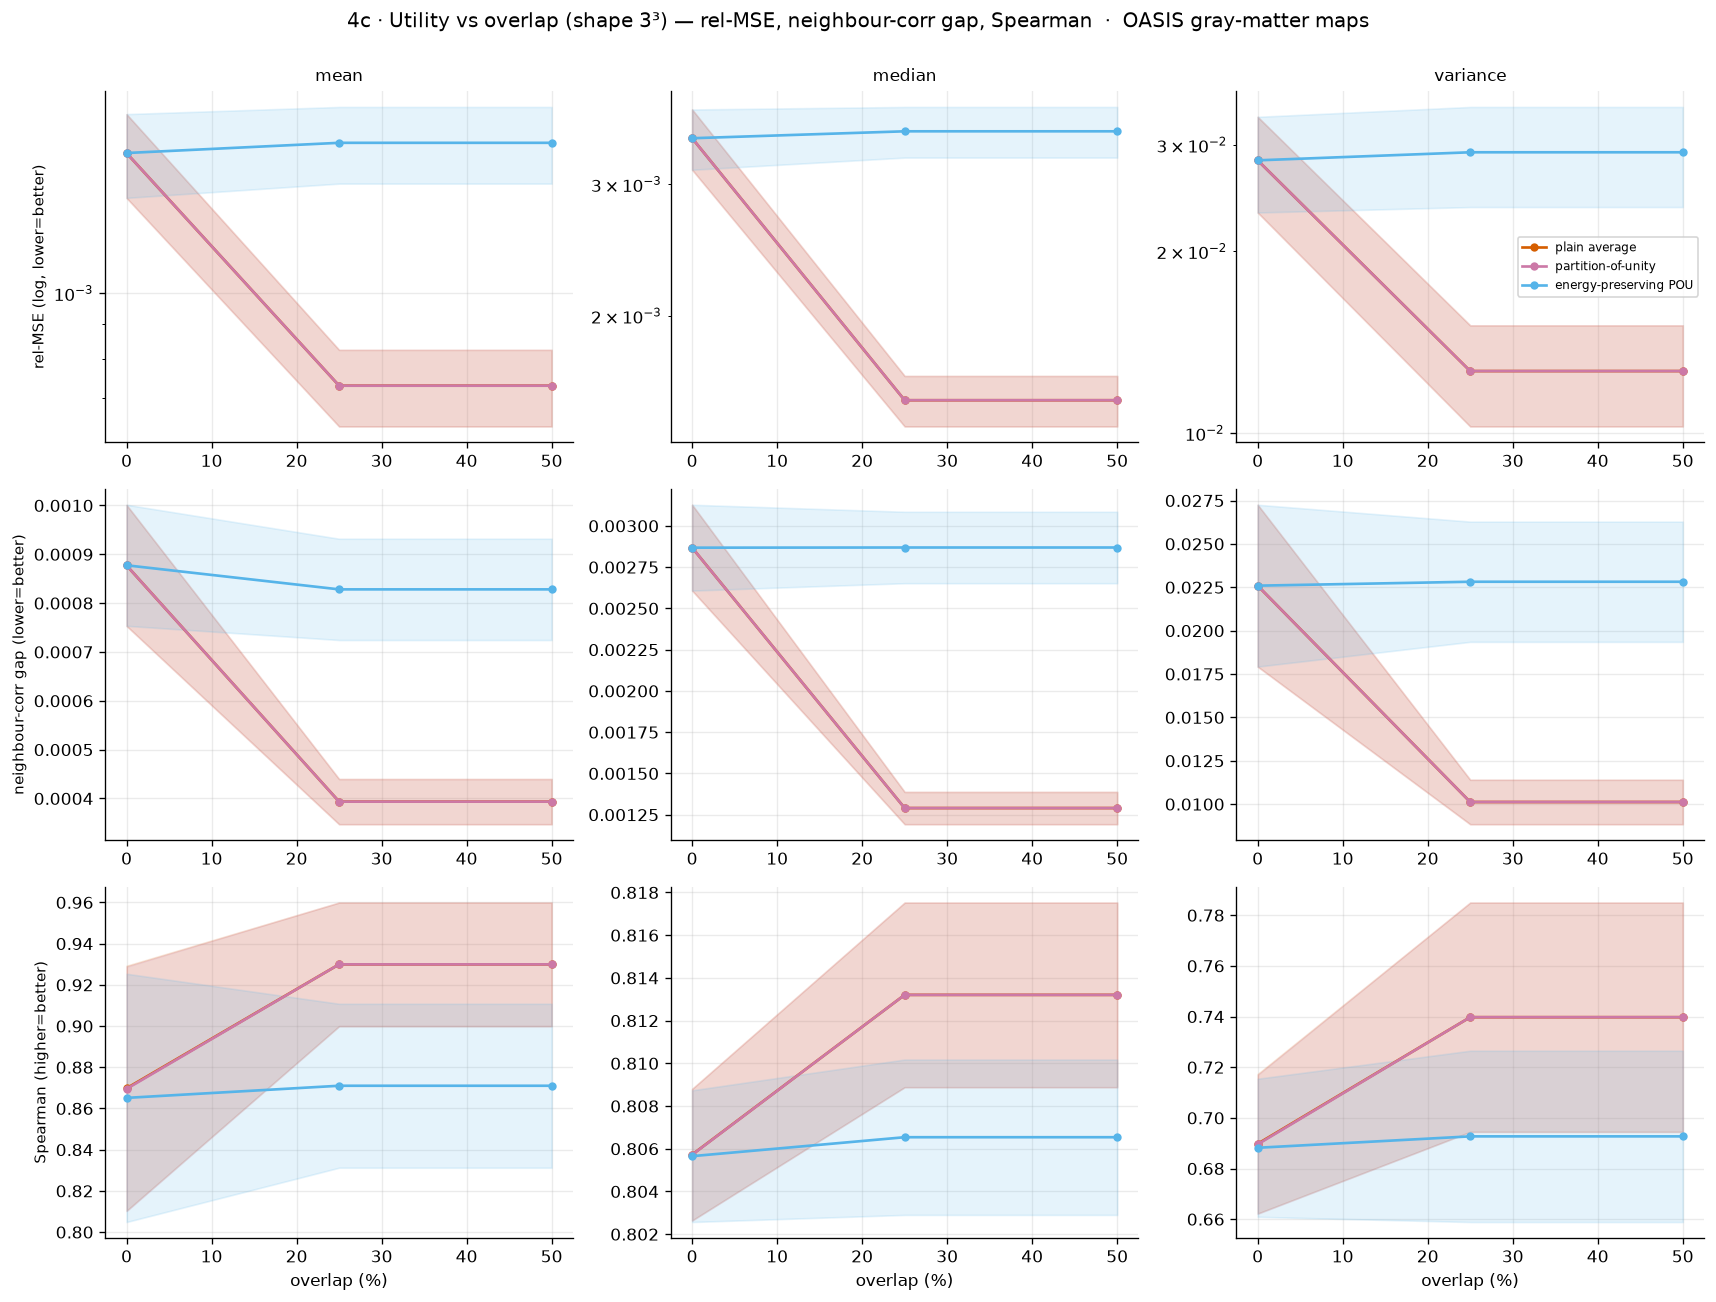

In [16]:
curve_shape = "3x3x3"
metrics = [("rel_mse","rel-MSE (log, lower=better)","log"),
           ("neighbour_corr_gap","neighbour-corr gap (lower=better)","linear"),
           ("spearman","Spearman (higher=better)","linear")]
fig, axes = plt.subplots(len(metrics), len(STATS), figsize=(4.8*len(STATS), 3.6*len(metrics)), squeeze=False)
for r,(metric,ylab,scale) in enumerate(metrics):
    for c, st in enumerate(STATS):
        a = axes[r,c]
        for b in BLENDS_REL:
            ys,los,his = [],[],[]
            for o in OVERLAPS:
                sub = UTIL[(UTIL.stat==st)&(UTIL.shp==curve_shape)&(UTIL.overlap==o)&(UTIL.blend==b)]
                m,lo,hi = ci95(sub[metric].values); ys.append(m); los.append(lo); his.append(hi)
            xx=[int(o*100) for o in OVERLAPS]
            a.plot(xx, ys, "o-", color=C_BLEND[b], lw=1.6, ms=4, label=BL_DISP[b])
            a.fill_between(xx, los, his, color=C_BLEND[b], alpha=0.15)
        a.set_yscale(scale)
        if r==0: a.set_title(st, fontsize=10)
        if r==len(metrics)-1: a.set_xlabel("overlap (%)")
        if c==0: a.set_ylabel(ylab, fontsize=9)
axes[0,-1].legend(fontsize=7)
fig.suptitle(f"4c · Utility vs overlap (shape {DISP[curve_shape]}) — rel-MSE, neighbour-corr gap, Spearman  ·  {SUBSTRATE}", y=1.0)
plt.tight_layout(); plt.show()

### 4d · Utility across shape × overlap

Each heatmap summarizes one metric over the full shape×overlap plane for the energy-POU release, per
statistic. **How the single rel-MSE number is computed:** for each configuration it is
`mean over in-brain voxels of (noise²)` divided by `mean over in-brain voxels of (clean signal²)`,
averaged over seeds — a whole-brain **relative mean squared error** (total noise power / total signal
power). We use the *mean* over voxels, not a median: MSE is an energy quantity, so the sum of squared
errors is the meaningful total, and the mean is that total per voxel; a median would hide the
high-error rim and seam voxels, which are exactly the privacy-relevant tail. The colour map is
oriented so **low rel-MSE is dark and high is bright**. SSIM (structural similarity, higher=better)
is shown alongside.

rel_mse: 135 matched seed values, 135 finite values, 0 empty grid cells.


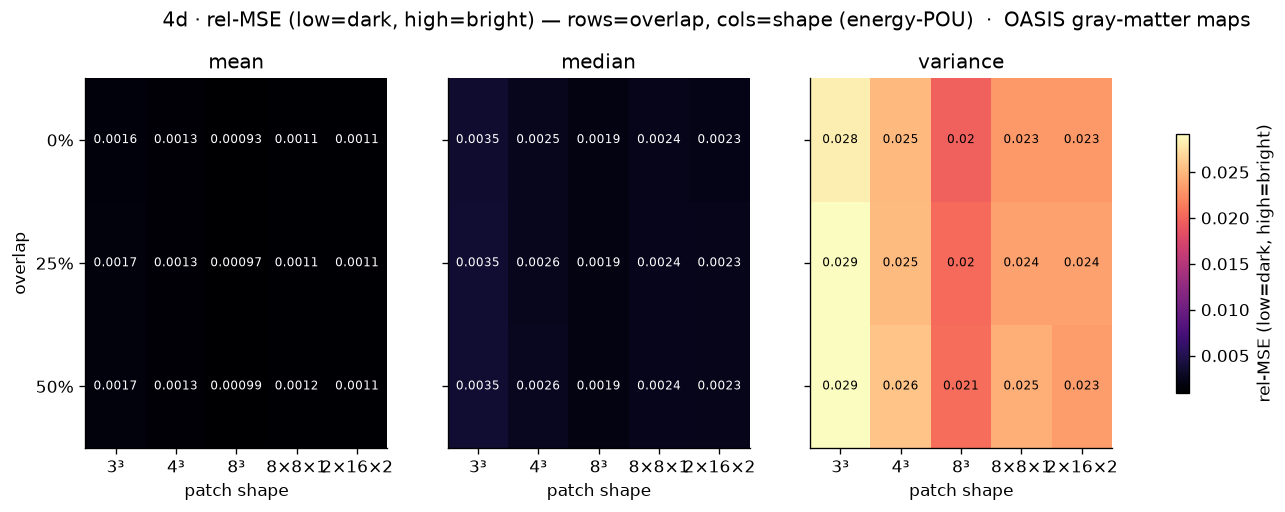

ssim: 135 matched seed values, 0 finite values, 0 empty grid cells.
Skipping ssim: no finite values to plot.


In [17]:
for metric, mlabel, cmap in [
    ("rel_mse", "rel-MSE (low=dark, high=bright)", "magma"),
    ("ssim", "SSIM (higher=better)", "viridis"),
]:
    M = {}
    matched = finite = empty_cells = 0

    for st in STATS:
        g = np.full((len(OVERLAPS), len(SHAPES)), np.nan)

        for i, o in enumerate(OVERLAPS):
            for j, nm in enumerate(SHAPES):
                sub = UTIL[
                    (UTIL["stat"] == st)
                    & (UTIL["shp"] == nm)
                    & (UTIL["overlap"] == o)
                    & (UTIL["blend"] == "pou_energy")
                ]

                values = sub[metric].to_numpy(dtype=float)
                matched += values.size
                empty_cells += int(values.size == 0)

                values = values[np.isfinite(values)]
                finite += values.size

                # A mean is defined even with only one valid seed.
                if values.size:
                    g[i, j] = values.mean()

        M[st] = g

    print(
        f"{metric}: {matched} matched seed values, "
        f"{finite} finite values, {empty_cells} empty grid cells.",
        flush=True,
    )

    allv = np.concatenate([M[st].ravel() for st in STATS])
    allv = allv[np.isfinite(allv)]

    if allv.size == 0:
        print(f"Skipping {metric}: no finite values to plot.")
        if matched == 0:
            print("Available labels:", {
                col: UTIL[col].unique().tolist()
                for col in ("stat", "shp", "overlap", "blend")
            })
        continue

    vmn, vmx = np.percentile(allv, [2, 98])

    # Keep the color scale usable if every value is identical.
    if vmn == vmx:
        pad = max(abs(vmn) * 0.01, 1e-9)
        vmn, vmx = vmn - pad, vmx + pad

    cmap_obj = plt.get_cmap(cmap).copy()
    cmap_obj.set_bad("lightgray")

    fig, axes = plt.subplots(
        1, len(STATS),
        figsize=(4.6 * len(STATS), 4.0),
        squeeze=False,
    )
    axes = axes[0]

    for a, st in zip(axes, STATS):
        im = a.imshow(
            np.ma.masked_invalid(M[st]),
            cmap=cmap_obj, vmin=vmn, vmax=vmx, aspect="auto",
        )
        a.grid(False)
        a.set_xticks(range(len(SHAPES)))
        a.set_xticklabels([DISP[nm] for nm in SHAPES])
        a.set_yticks(range(len(OVERLAPS)))
        a.set_yticklabels(
            [f"{int(o * 100)}%" for o in OVERLAPS]
            if a is axes[0] else []
        )
        a.set_title(st)
        a.set_xlabel("patch shape")
        if a is axes[0]:
            a.set_ylabel("overlap")

        for i in range(len(OVERLAPS)):
            for j in range(len(SHAPES)):
                v = M[st][i, j]
                if not np.isfinite(v):
                    a.text(j, i, "n/a", ha="center", va="center",
                           fontsize=7, color="k")
                    continue

                frac = np.clip((v - vmn) / (vmx - vmn), 0, 1)
                rr, gg, bb, _ = cmap_obj(frac)
                color = "w" if 0.299*rr + 0.587*gg + 0.114*bb < 0.5 else "k"
                a.text(j, i, f"{v:.2g}", ha="center", va="center",
                       fontsize=7, color=color)

    fig.colorbar(im, ax=axes, shrink=0.7, label=mlabel)
    fig.suptitle(
        f"4d · {mlabel} — rows=overlap, cols=shape "
        f"(energy-POU)  ·  {SUBSTRATE}",
        y=1.02,
    )
    plt.show()

## 5 · Patch-rank distribution

Each patch's noise covariance has a structural rank — read from the **raw** Cov(LOO) perturbations
(the mechanism floors its sampling covariance to full rank, so that regularized object would hide
this). Two different numbers live here, and it matters which one is quoted for privacy:

- **Full (numerical) rank** — the count of non-zero LOO modes, capped at min(p, N−1)=min(p, 39). This
  is the **privacy-relevant** rank: notebook 6.1 showed leakage lives in *all* of these modes,
  including the low-variance tail, so the noise must cover the full rank — it **cannot** be truncated.
- **95%-energy effective rank** — how many modes hold 95% of the noise *energy* (small here). This is
  a **structural descriptor** of where the noise concentrates, **not** a privacy budget. A low
  effective rank does *not* license truncation (the fallacy 6.1 refuted).

Rank is a property of each patch, independent of overlap; overlap only changes how many patches there
are and where they sit.

**What the annotation `well-estimated (total)` means.** Every patch tiled at a setting is a *total*
patch, and that includes the boundary coverage-fill patches added (§4) so no voxel goes unprotected.
Those boundary patches contain only a few in-brain voxels, so their covariance — and hence their rank
— is artificially low and would drag the distribution down. A patch is **well-estimated** when its
in-brain fraction ≥ `min_frac` (0.5): enough in-brain voxels for a trustworthy covariance. The violin
is drawn from the well-estimated patches only; the annotation reads `<#well-estimated> (<#total>)`, so
`183 (226)` means 183 well-estimated patches shown out of 226 patches tiled in all.

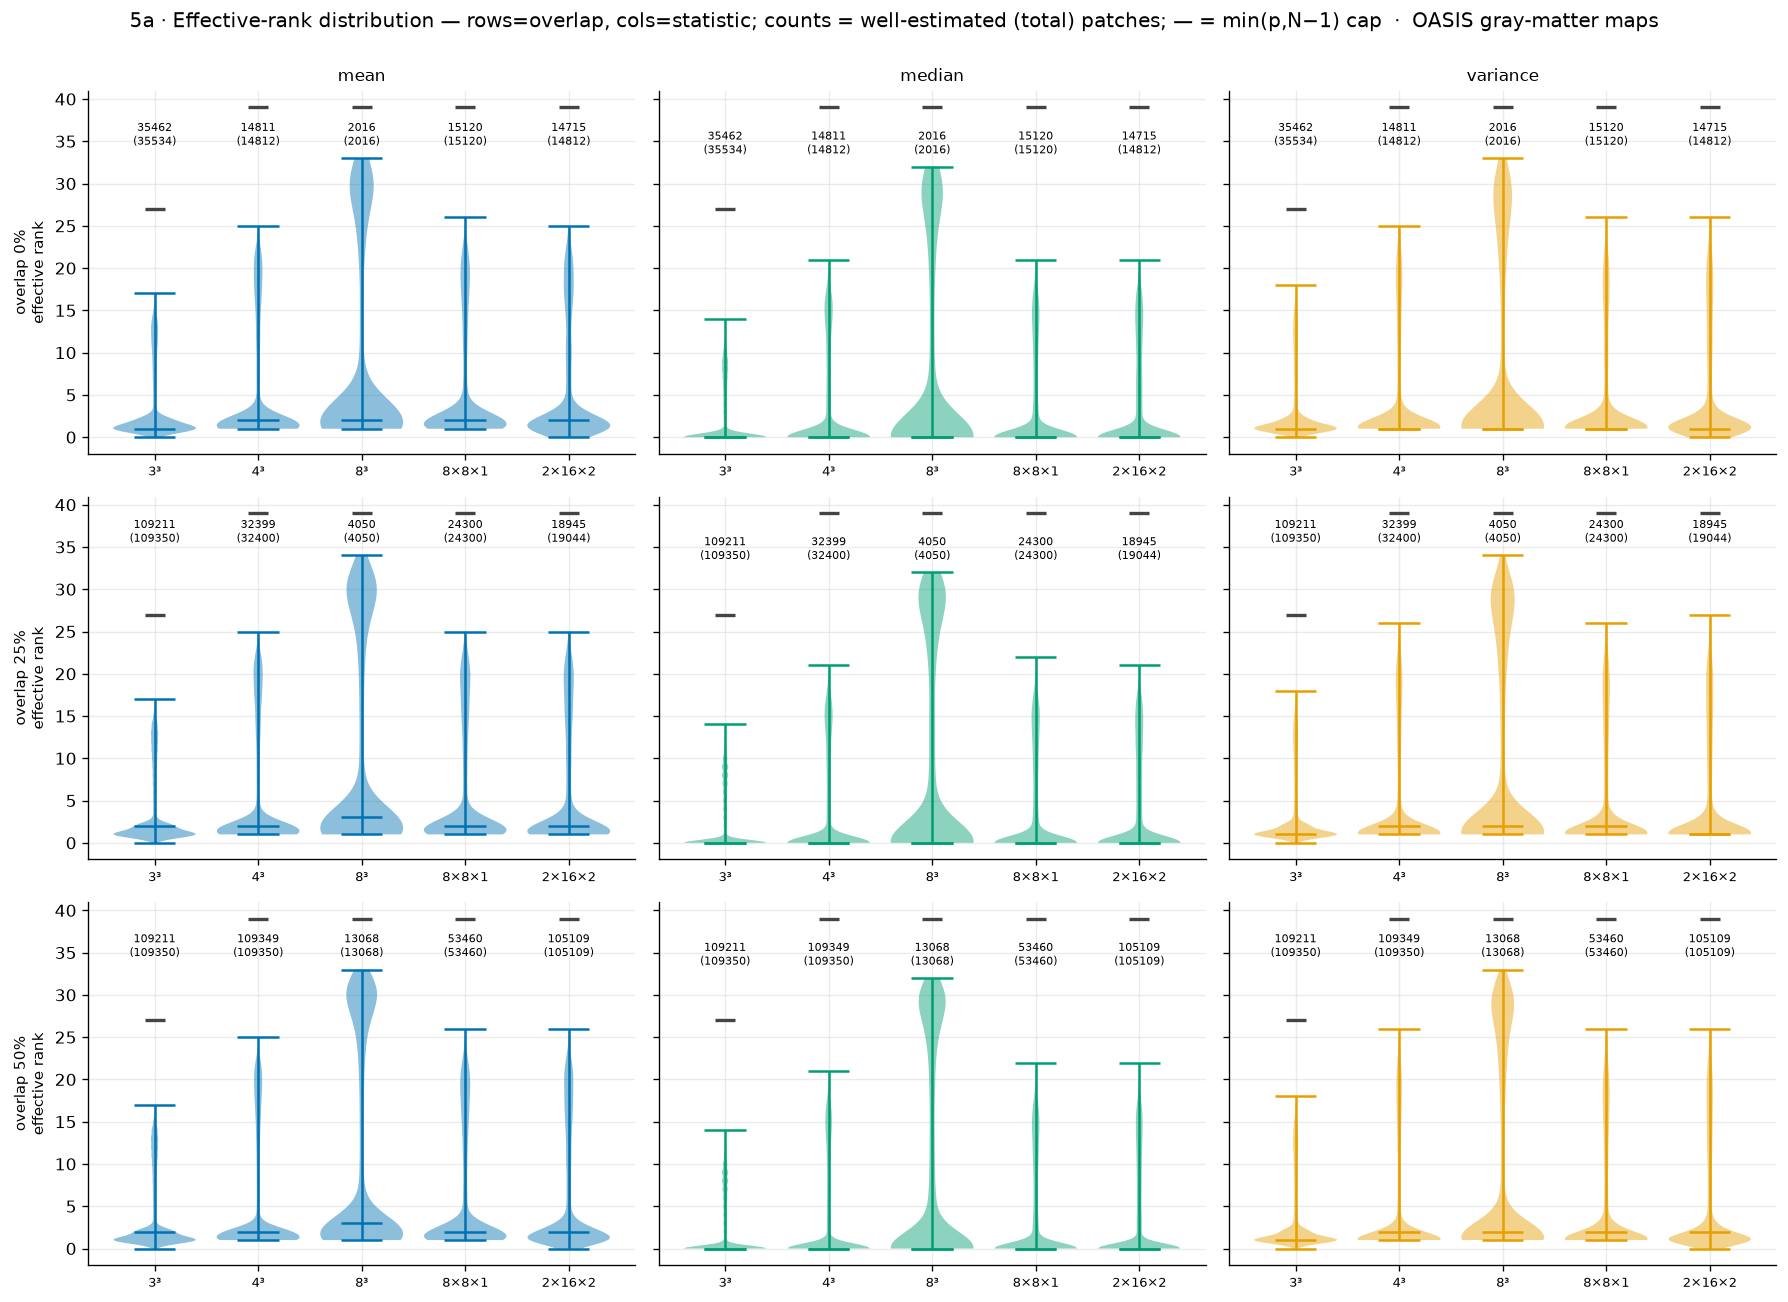

In [18]:
# Figure 5a — effective-rank violins: rows = overlap, cols = statistic, one violin per shape, counts annotated
fig, axes = plt.subplots(len(OVERLAPS), len(STATS), figsize=(5*len(STATS), 3.6*len(OVERLAPS)), squeeze=False, sharey=True)
for r, o in enumerate(OVERLAPS):
    for c, st in enumerate(STATS):
        a = axes[r,c]
        data, counts = [], []
        for nm in SHAPES:
            R = SW[(st,nm,o)]; q = R["patch_frac"] >= MIN_FRAC
            data.append(R["eff"][q] if q.any() else np.array([0]))
            counts.append((int(q.sum()), int(len(R["eff"]))))
        parts = a.violinplot(data, showmedians=True, widths=0.8)
        for pc in parts["bodies"]: pc.set_facecolor(C_STAT[st]); pc.set_alpha(0.45)
        for key in ("cmedians","cbars","cmins","cmaxes"):
            if key in parts: parts[key].set_color(C_STAT[st])
        for i, nm in enumerate(SHAPES):
            cap = min(int(np.prod(SHAPES[nm])), N-1); a.plot(i+1, cap, "_", color="#444", ms=12, mew=2)
            top = max([d.max() for d in data if len(d)]+[1])
            a.text(i+1, top*1.02+0.5, f"{counts[i][0]}\n({counts[i][1]})", ha="center", va="bottom", fontsize=6.5)
        a.set_xticks(range(1,len(SHAPES)+1)); a.set_xticklabels([DISP[n] for n in SHAPES], fontsize=8)
        if r==0: a.set_title(st, fontsize=10)
        if c==0: a.set_ylabel(f"overlap {int(o*100)}%\neffective rank", fontsize=9)
fig.suptitle(f"5a · Effective-rank distribution — rows=overlap, cols=statistic; counts = well-estimated (total) patches; "
             f"— = min(p,N−1) cap  ·  {SUBSTRATE}", y=1.0)
plt.tight_layout(); plt.show()

**Shape at matched volume.** The three ~64-voxel shapes (4³, flat 8×8×1, column 2×2×16) isolate
the effect of patch *shape* at fixed voxel count, for the mean at 50% overlap.

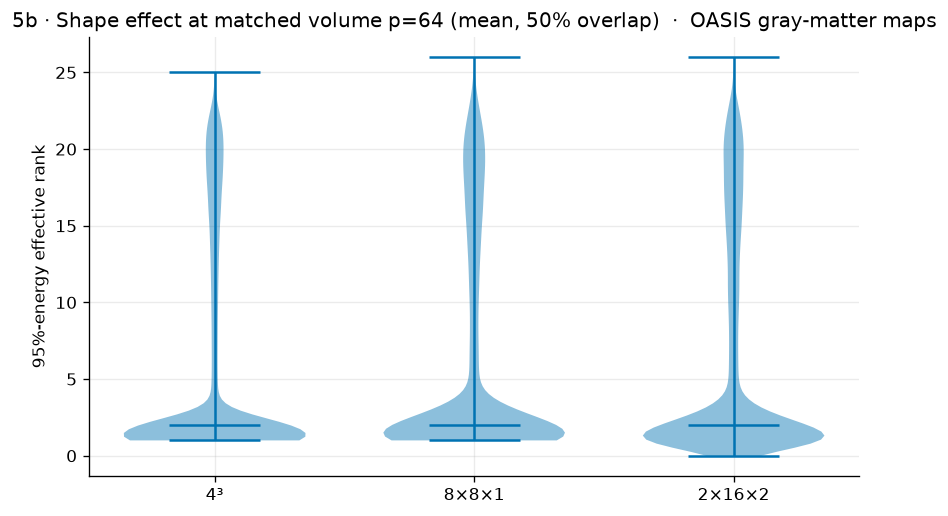

In [19]:
matched = [n for n in ["4x4x4","8x8x1","2x16x2"] if n in SHAPES]
fig, ax = plt.subplots(figsize=(7.2, 4.4))
data = [SW[("mean",nm,0.5)]["eff"][SW[("mean",nm,0.5)]["patch_frac"]>=MIN_FRAC] for nm in matched]
parts = ax.violinplot(data, showmedians=True, widths=0.7)
for pc in parts["bodies"]: pc.set_facecolor("#0072B2"); pc.set_alpha(0.45)
for key in ("cmedians","cbars","cmins","cmaxes"):
    if key in parts: parts[key].set_color("#0072B2")
ax.set_xticks(range(1,len(matched)+1)); ax.set_xticklabels([DISP[n] for n in matched])
ax.set_ylabel("95%-energy effective rank")
ax.set_title(f"5b · Shape effect at matched volume p=64 (mean, 50% overlap)  ·  {SUBSTRATE}")
plt.tight_layout(); plt.show()

**Effective rank across the brain.** Each patch is drawn at its centre, coloured by its effective
rank. Rank is per-patch and overlap-independent, so we hold overlap at 50% and vary the two things
that actually move it: **patch size** (columns 4³, 6³, 8³) and **statistic** (rows mean, variance —
the two extremes; median sits between). One axial slice each. Look for spatial structure: smoother
regions concentrate energy in fewer modes (lower rank) than textured regions.

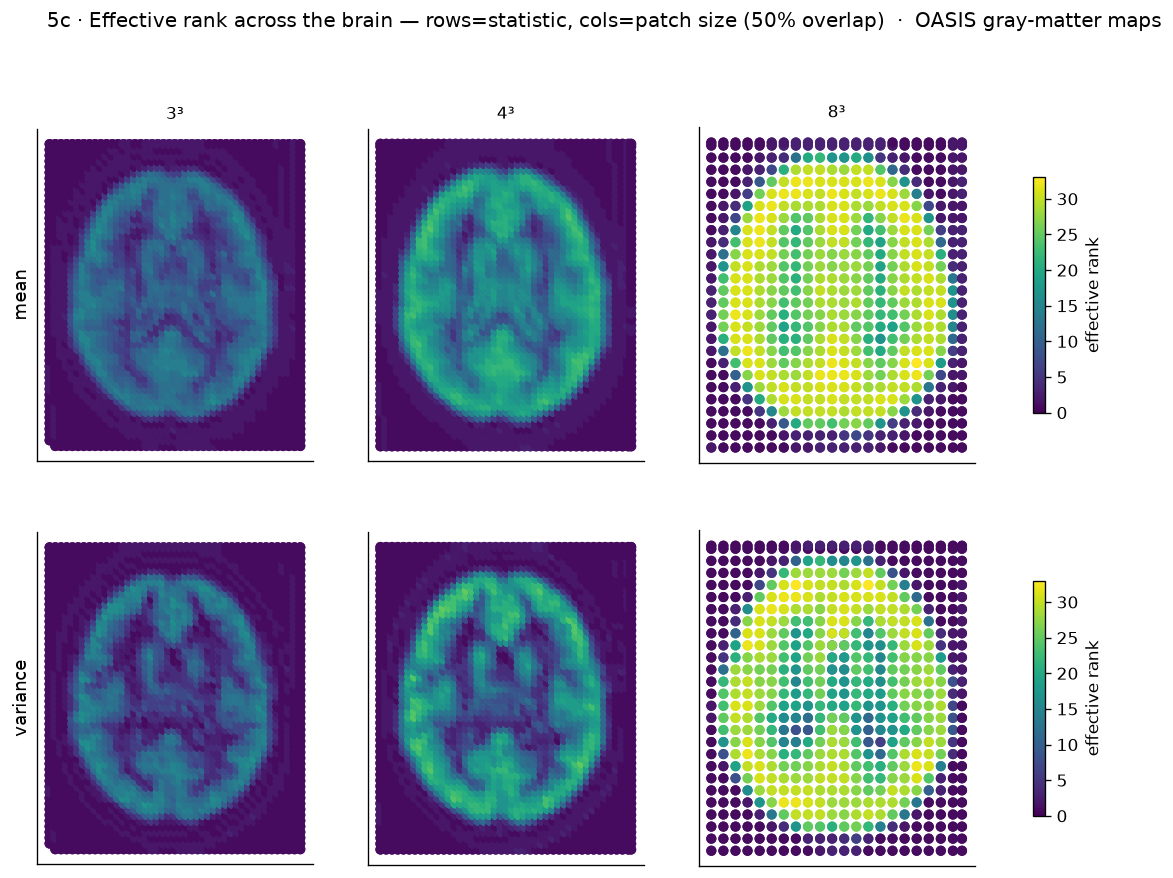

In [20]:
sel_stats = ["mean","variance"]; sel_shapes = [n for n in ["3x3x3","4x4x4","8x8x8"] if n in SHAPES]
fig, axes = plt.subplots(len(sel_stats), len(sel_shapes), figsize=(4.2*len(sel_shapes), 4.0*len(sel_stats)), squeeze=False)
for r, st in enumerate(sel_stats):
    evs = np.concatenate([SW[(st,nm,0.5)]["eff"][SW[(st,nm,0.5)]["patch_frac"]>=MIN_FRAC] for nm in sel_shapes])
    vmn, vmx = (evs.min(), evs.max()) if evs.size else (0,1)
    for c, nm in enumerate(sel_shapes):
        R = SW[(st,nm,0.5)]; q = R["patch_frac"]>=MIN_FRAC; cen=R["centers"][q]; ev=R["eff"][q]
        selz = np.abs(cen[:,2]-zc) <= max(SHAPES[nm])/2
        sc = axes[r,c].scatter(cen[selz,0], cen[selz,1], c=ev[selz], cmap=CMAP_RANK, s=26, vmin=vmn, vmax=vmx)
        axes[r,c].set_aspect("equal"); axes[r,c].grid(False); axes[r,c].set_xticks([]); axes[r,c].set_yticks([])
        if r==0: axes[r,c].set_title(DISP[nm], fontsize=10)
        if c==0: axes[r,c].set_ylabel(st, fontsize=11)
    plt.colorbar(sc, ax=axes[r,:], shrink=0.7, label="effective rank")
fig.suptitle(f"5c · Effective rank across the brain — rows=statistic, cols=patch size (50% overlap)  ·  {SUBSTRATE}", y=1.0)
plt.show()

**Effective rank vs patch size.** Median effective rank (with IQR band) against patch volume for
the cubic sizes, per statistic — the saturation toward the N−1 ceiling as patches grow.

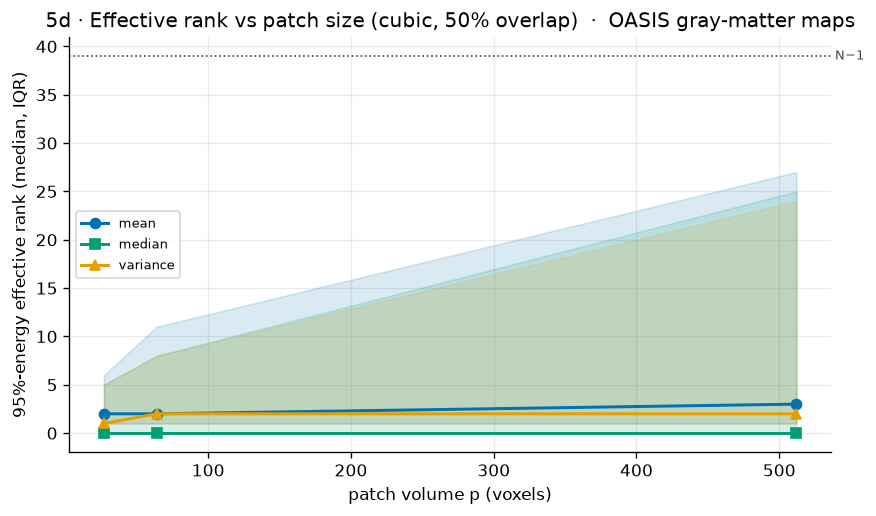

In [21]:
fig, ax = plt.subplots(figsize=(7.4, 4.4)); cubic=[n for n in ["3x3x3","4x4x4","8x8x8"] if n in SHAPES]
for st in STATS:
    ps_,med,lo,hi = [],[],[],[]
    for nm in cubic:
        e = SW[(st,nm,0.5)]["eff"][SW[(st,nm,0.5)]["patch_frac"]>=MIN_FRAC]
        ps_.append(int(np.prod(SHAPES[nm]))); med.append(np.median(e)); lo.append(np.percentile(e,25)); hi.append(np.percentile(e,75))
    ax.plot(ps_, med, "-", color=C_STAT[st], marker=M_STAT[st], ms=6, lw=1.8, label=st); ax.fill_between(ps_,lo,hi,color=C_STAT[st],alpha=0.15)
ax.axhline(N-1, color="#444", ls=":", lw=1); ax.text(ax.get_xlim()[1], N-1, " N−1", va="center", fontsize=8, color="#444")
ax.set_xlabel("patch volume p (voxels)"); ax.set_ylabel("95%-energy effective rank (median, IQR)")
ax.set_title(f"5d · Effective rank vs patch size (cubic, 50% overlap)  ·  {SUBSTRATE}"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

In [22]:
break

SyntaxError: 'break' outside loop (668683560.py, line 1)

## 6 · Custom patch sizes

The full §4 + §5 treatment on your own sizes from the 6.3 autocorrelation study (edit `CUSTOM_SIZES`
in §0). The committed run keeps the custom overlap set light (`CUSTOM_OVERLAPS`); widen it in your
environment. The noise-field comparison is shown for mean, median **and** variance.

In [ ]:
import time
from datetime import timedelta

def _duration(seconds):
    return str(timedelta(seconds=int(round(seconds))))

CS = {
    k: v for k, v in CUSTOM_SIZES.items()
    if all(s <= d for s, d in zip(v, VOLSHAPE))
}

if not CS:
    print("no CUSTOM_SIZES fit the volume; skipping §6")
    SWC = {}
    CUTIL = pd.DataFrame()

else:
    n_configs = len(STATS) * len(CS) * len(CUSTOM_OVERLAPS)
    n_runs = n_configs * len(SEEDS)
    completed = 0

    SWC = {}
    cu_rows = []
    t0 = time.perf_counter()

    print(
        f"Starting custom sweep: {n_configs} configs × {len(SEEDS)} seeds "
        f"= {n_runs} runs; {len(BLENDS_REL)} blends per run.\n"
        "Estimated time remaining will appear after the first run.",
        flush=True,
    )

    for st in STATS:
        for nm, ps in CS.items():
            for o in CUSTOM_OVERLAPS:
                for si, seed in enumerate(SEEDS):
                    print(
                        f"[{completed + 1}/{n_runs}] Starting: "
                        f"stat={st} | shape={nm} {ps} | "
                        f"overlap={o} | seed={seed}",
                        flush=True,
                    )
                    run_t0 = time.perf_counter()

                    R = T.assemble_field(
                        COHORT[seed], MASK, st, ps, o,
                        epsilon=EPSILON,
                        base_seed=1000 * seed,
                        min_frac=MIN_FRAC,
                        n_jobs=40,
                        # n_jobs=NJOBS,
                        mech_kind=MECH_KIND,
                    )

                    if si == 0:
                        SWC[(st, nm, o)] = R

                    for b in BLENDS_REL:
                        U = T.whole_brain_utility(
                            R["clean"], R["fields"][b], MASK
                        )
                        cu_rows.append({
                            "stat": st,
                            "shp": nm,
                            "overlap": o,
                            "blend": b,
                            "seed": seed,
                            **U,
                        })

                    completed += 1
                    now = time.perf_counter()
                    elapsed = now - t0
                    remaining = (
                        elapsed / completed
                    ) * (n_runs - completed)

                    print(
                        f"    Finished in {_duration(now - run_t0)} | "
                        f"{completed / n_runs:.1%} complete | "
                        f"elapsed {_duration(elapsed)} | "
                        f"remaining ≈ {_duration(remaining)}",
                        flush=True,
                    )

    CUTIL = pd.DataFrame(cu_rows)

    print(
        f"\nCustom sweep complete: {len(SWC)} configs × "
        f"{len(SEEDS)} seeds × {len(BLENDS_REL)} blends in "
        f"{_duration(time.perf_counter() - t0)}.",
        flush=True,
    )

In [ ]:
# 6a — noise-field comparison for mean/median/variance (rows=custom size, cols=statistic), 50% overlap
if CS:
    o_use = 0.5 if 0.5 in CUSTOM_OVERLAPS else CUSTOM_OVERLAPS[-1]
    fig, axes = plt.subplots(len(CS), len(STATS), figsize=(3.6*len(STATS), 3.3*len(CS)), squeeze=False)
    for i, nm in enumerate(CS):
        allf = np.concatenate([SWC[(st,nm,o_use)]["fields"]["pou_energy"][MASK] for st in STATS])
        vmn, vmx = robust_sym(allf)
        for j, st in enumerate(STATS):
            im = show(axes[i,j], np.where(MASK, SWC[(st,nm,o_use)]["fields"]["pou_energy"], np.nan)[:,:,zc].T,
                      CMAP_DIV, vmin=vmn, vmax=vmx, outline=MASK_AX, title=st if i==0 else None)
            if j==0: axes[i,j].set_ylabel(nm, fontsize=10)
        plt.colorbar(im, ax=axes[i,:], shrink=0.7, label="noise (energy-POU)")
    fig.suptitle(f"6a · Custom-size noise fields — rows=size, cols=statistic ({int(o_use*100)}% overlap)  ·  {SUBSTRATE}", y=1.0)
    plt.show()

In [ ]:
# 6b — utility vs overlap for custom sizes (rel-MSE / gap / Spearman), mean, blend lines
if CS:
    metrics=[("rel_mse","rel-MSE (log)","log"),("neighbour_corr_gap","nbr-corr gap","linear"),("spearman","Spearman","linear")]
    fig, axes = plt.subplots(len(metrics), len(CS), figsize=(4.8*len(CS), 3.4*len(metrics)), squeeze=False)
    for r,(metric,ylab,scale) in enumerate(metrics):
        for c, nm in enumerate(CS):
            a=axes[r,c]
            for b in BLENDS_REL:
                ys,los,his=[],[],[]
                for o in CUSTOM_OVERLAPS:
                    sub=CUTIL[(CUTIL.stat=="mean")&(CUTIL.shp==nm)&(CUTIL.overlap==o)&(CUTIL.blend==b)]
                    m,lo,hi=ci95(sub[metric].values); ys.append(m); los.append(lo); his.append(hi)
                xx=[int(o*100) for o in CUSTOM_OVERLAPS]
                a.plot(xx,ys,"o-",color=C_BLEND[b],lw=1.5,ms=4,label=BL_DISP[b]); a.fill_between(xx,los,his,color=C_BLEND[b],alpha=0.15)
            a.set_yscale(scale)
            if r==0: a.set_title(nm, fontsize=10)
            if r==len(metrics)-1: a.set_xlabel("overlap (%)")
            if c==0: a.set_ylabel(ylab, fontsize=9)
    axes[0,-1].legend(fontsize=7)
    fig.suptitle(f"6b · Custom-size utility vs overlap (mean)  ·  {SUBSTRATE}", y=1.0); plt.tight_layout(); plt.show()

In [ ]:
# 6c — rank violins (counts) + rank-on-brain for custom sizes
if CS:
    o_use = 0.5 if 0.5 in CUSTOM_OVERLAPS else CUSTOM_OVERLAPS[-1]
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
    data=[]; counts=[]
    for nm in CS:
        R=SWC[("mean",nm,o_use)]; q=R["patch_frac"]>=MIN_FRAC
        data.append(R["eff"][q] if q.any() else np.array([0])); counts.append((int(q.sum()),int(len(R["eff"]))))
    parts=axes[0].violinplot(data, showmedians=True, widths=0.7)
    for pc in parts["bodies"]: pc.set_facecolor("#0072B2"); pc.set_alpha(0.45)
    for key in ("cmedians","cbars","cmins","cmaxes"):
        if key in parts: parts[key].set_color("#0072B2")
    for i,nm in enumerate(CS):
        cap=min(int(np.prod(CS[nm])),N-1); axes[0].plot(i+1,cap,"_",color="#444",ms=12,mew=2)
        axes[0].text(i+1, max([d.max() for d in data if len(d)]+[1])*1.02, f"{counts[i][0]}\n({counts[i][1]})", ha="center", va="bottom", fontsize=7)
    axes[0].set_xticks(range(1,len(CS)+1)); axes[0].set_xticklabels(list(CS)); axes[0].set_ylabel("effective rank")
    axes[0].set_title(f"custom effective rank ({int(o_use*100)}% overlap)  ·  counts = well-est (total)")
    nm0=list(CS)[0]; R=SWC[("mean",nm0,o_use)]; q=R["patch_frac"]>=MIN_FRAC; cen=R["centers"][q]; ev=R["eff"][q]
    selz=np.abs(cen[:,2]-zc)<=max(CS[nm0])/2
    sc=axes[1].scatter(cen[selz,0],cen[selz,1],c=ev[selz],cmap=CMAP_RANK,s=26); axes[1].set_aspect("equal")
    axes[1].grid(False); axes[1].set_xticks([]); axes[1].set_yticks([]); axes[1].set_title(f"{nm0} rank-on-brain (mean)")
    plt.colorbar(sc, ax=axes[1], shrink=0.8, label="effective rank")
    fig.suptitle(f"6c · Custom-size rank distribution and spatial map  ·  {SUBSTRATE}", y=1.02); plt.tight_layout(); plt.show()

## 7 · Design space

Every tiling as one point: median effective rank (the noise degrees of freedom) against utility
(rel-MSE of the energy-POU release). This compresses the whole sweep. **Encoding:** marker **colour**
= statistic, marker **shape** = patch shape, marker **size** = overlap (bigger marker = more overlap).
So points that share a shape but differ in size are the same patch shape at different overlap levels.

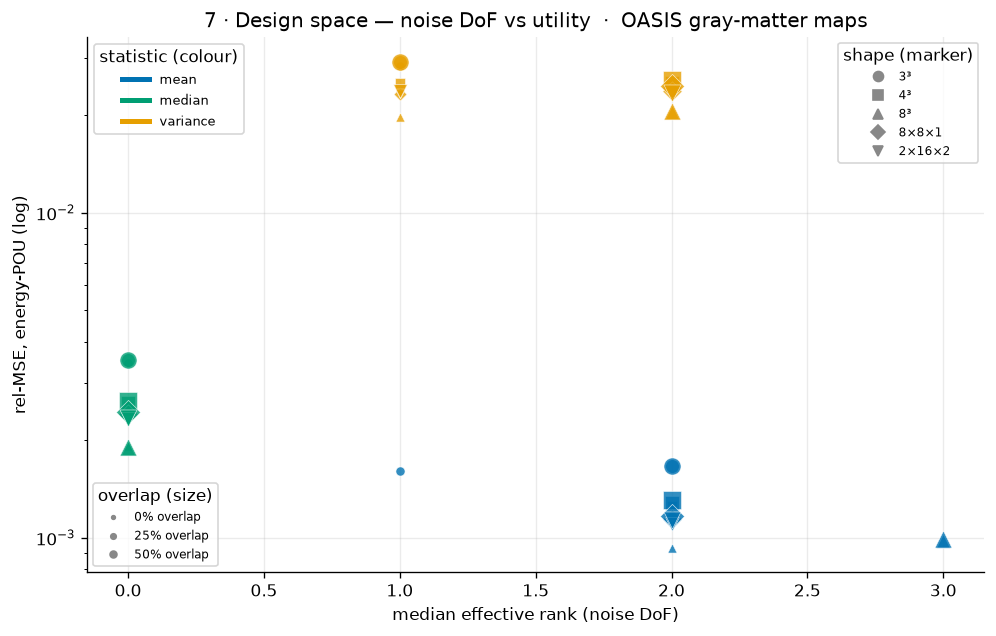

In [23]:
fig, ax = plt.subplots(figsize=(8.4, 5.4))
shape_marker = {nm:m for nm,m in zip(SHAPES, ["o","s","^","D","v","P","X","*"])}
for st in STATS:
    for nm in SHAPES:
        for o in OVERLAPS:
            rank_med = np.median(SW[(st,nm,o)]["eff"][SW[(st,nm,o)]["patch_frac"]>=MIN_FRAC])
            rm = ci95(UTIL[(UTIL.stat==st)&(UTIL.shp==nm)&(UTIL.overlap==o)&(UTIL.blend=="pou_energy")].rel_mse.values)[0]
            ax.scatter(rank_med, rm, color=C_STAT[st], marker=shape_marker[nm], s=30+150*o, alpha=0.8, edgecolor="w", lw=0.4)
ax.set_yscale("log"); ax.set_xlabel("median effective rank (noise DoF)"); ax.set_ylabel("rel-MSE, energy-POU (log)")
h_stat  = [Line2D([0],[0], color=C_STAT[s], lw=3, label=s) for s in STATS]
h_shape = [Line2D([0],[0], color="#888", marker=shape_marker[n], ls="", label=DISP[n]) for n in SHAPES]
h_size  = [Line2D([0],[0], color="#888", marker="o", ls="", ms=np.sqrt(30+150*o)/2.5, label=f"{int(o*100)}% overlap") for o in OVERLAPS]
leg1 = ax.legend(handles=h_stat, fontsize=8, loc="upper left", title="statistic (colour)")
leg2 = ax.legend(handles=h_shape, fontsize=7, loc="upper right", title="shape (marker)")
leg3 = ax.legend(handles=h_size, fontsize=7, loc="lower left", title="overlap (size)")
ax.add_artist(leg1); ax.add_artist(leg2)
ax.set_title(f"7 · Design space — noise DoF vs utility  ·  {SUBSTRATE}")
plt.tight_layout(); plt.show()